# Task 2 - Deep Learning
Kelompok: K10

## 1. Persiapan dan konfigurasi

In [1]:
import importlib.util, subprocess, sys

required = {
    'numpy': 'numpy', 'pandas': 'pandas', 'PIL': 'Pillow', 'matplotlib': 'matplotlib',
    'sklearn': 'scikit-learn', 'scipy': 'scipy', 'cv2': 'opencv-python',
    'torch': 'torch', 'torchvision': 'torchvision', 'tqdm': 'tqdm', 'gdown': 'gdown',
    'segmentation_models_pytorch': 'segmentation-models-pytorch',
}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import json, zipfile, hashlib, pickle
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score, balanced_accuracy_score,
)

DATA_URL = 'https://drive.google.com/file/d/1M1IRpFds1VyIkc9IJBehrprcjAEaPXSw/view?usp=sharing'
HIDDEN_URL = 'https://drive.google.com/file/d/1Jkl9WL75xv_Gxb24kaDKE48Q1q6iYFYJ/view?usp=sharing'
LOCAL_ZIP = ''
DATA_DIR = ''
HIDDEN_ZIP = ''
HIDDEN_DATA_DIR = ''
REFERENCE_OVERRIDE = ''

# Path resolver seragam: mendukung eksekusi lokal (root/notebooks) dan Google Colab (Drive /content)
def _resolve_repo_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd.parent,
        Path('/content/drive/MyDrive/Comvis/Mini_Project'),
        Path('/content/drive/MyDrive/COMVIS/Mini_Project'),
        Path('/content/drive/MyDrive/Mini_Project'),
        Path('/content/Mini_Project'),
    ]
    for cand in candidates:
        if (cand / 'data').is_dir() or (cand / 'template_all').is_dir() or (cand / 'notebooks').is_dir():
            return cand.resolve()
    return cwd.parent if cwd.name == 'notebooks' else cwd

def _resolve_existing_path(override, rel_candidates, colab_candidates):
    if override:
        p = Path(override)
        return p if p.exists() else None
    for rel in rel_candidates:
        p = REPO_ROOT / rel
        if p.exists():
            return p
    for abs_p in colab_candidates:
        p = Path(abs_p)
        if p.exists():
            return p
    return None

REPO_ROOT = _resolve_repo_root()
WORK_DIR = Path('/content/gingerbread_cache/task2_dl') if str(REPO_ROOT).startswith('/content/drive') else (REPO_ROOT / 'scratch' / 'task2_dl')
SUBMISSION_DIR = REPO_ROOT / 'submissions' / 'submission_tugas2_dl'
MODEL_DIR = (REPO_ROOT / 'models') if (REPO_ROOT / 'models' / 'task2_face_unet.pt').exists() else (WORK_DIR / 'models')

TRAIN_ZIP = _resolve_existing_path(
    LOCAL_ZIP,
    ['data/gingerbread_seed2026_students_training.zip'],
    [
        '/content/drive/MyDrive/Comvis/Mini_Project/data/gingerbread_seed2026_students_training.zip',
        '/content/drive/MyDrive/COMVIS/Mini_Project/data/gingerbread_seed2026_students_training.zip',
        '/content/gingerbread_seed2026_students_training.zip',
        '/content/data/gingerbread_seed2026_students_training.zip',
    ],
)
HIDDEN_ZIP_PATH = _resolve_existing_path(
    HIDDEN_ZIP,
    ['data/hidden_students.zip'],
    [
        '/content/drive/MyDrive/Comvis/Mini_Project/data/hidden_students.zip',
        '/content/drive/MyDrive/COMVIS/Mini_Project/data/hidden_students.zip',
        '/content/hidden_students.zip',
        '/content/data/hidden_students.zip',
    ],
)
REFERENCE_DIR = _resolve_existing_path(
    REFERENCE_OVERRIDE,
    ['template_all'],
    [
        '/content/drive/MyDrive/Comvis/Mini_Project/template_all',
        '/content/drive/MyDrive/COMVIS/Mini_Project/template_all',
        '/content/template_all',
    ],
) or (REPO_ROOT / 'template_all')

LEADERBOARD = True       # 10-column submission
EVAL_SPLIT = 'test'      # labelled split used for optional evaluation
RUN_PREDICTIONS = True
SEED = 2026

np.random.seed(SEED)
FACES = ('front', 'right', 'top')
SINGLE_COLS = ['image_id', 'is_defective', 'defect_score']

def cube_columns(leaderboard=False):
    fields = ['total', 'defective'] + (['design_count'] if leaderboard else [])
    return ['image_id'] + [f'{face}_{field}' for field in fields for face in FACES]

CUBE_COLS = cube_columns(LEADERBOARD)
print('Repo root:', REPO_ROOT)
print('Reference dir:', REFERENCE_DIR)
print('Submission dir:', SUBMISSION_DIR)
print('Kolom Tugas 2:', CUBE_COLS)

Repo root: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project
Reference dir: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\template_all
Submission dir: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\submissions\submission_tugas2_dl
Kolom Tugas 2: ['image_id', 'front_total', 'right_total', 'top_total', 'front_defective', 'right_defective', 'top_defective', 'front_design_count', 'right_design_count', 'top_design_count']


In [2]:
from __future__ import annotations

import argparse
import json
import os
import pickle
import random
import time
from pathlib import Path
from typing import Iterable

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

import segmentation_models_pytorch as smp

FACES = ("front", "right", "top")
FACE_TO_ID = {name: i + 1 for i, name in enumerate(FACES)}

SEED = 2026
FACE_INPUT = 256
OBJECT_PAD = 0.15
REFERENCE_PAD = 0.10
DINO_MIN_SIM = 0.30
MAX_DEFECTS_PER_CUBE = 2
DEFECT_THRESHOLD = 0.70

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

FEATURE_NAMES = [
    "sim",
    "margin",
    "inliers",
    "coverage",
    "overlap_frac",
    "stain",
    "meande",
    "area",
    "aspect",
    "cov_def",
    "sim_low",
]

# Basic I/O and data helpers
def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def default_device() -> str:
    return "cuda" if torch.cuda.is_available() else "cpu"


def read_rgb(path: str | Path) -> np.ndarray:
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB"))


def load_references(reference_dir: str | Path) -> dict[int, dict]:
    """Load references from a `references/` directory or `template_all/`.

    If `designs.json` is available it is used. Otherwise every PNG/JPG in the
    directory becomes one design, sorted by filename so IDs are stable.
    """
    root = Path(reference_dir)
    if root.name == "references":
        ref_dir = root
    elif (root / "references").is_dir():
        ref_dir = root / "references"
    else:
        ref_dir = root

    designs_path = ref_dir / "designs.json"
    if designs_path.exists():
        records = json.loads(designs_path.read_text())
    else:
        files = sorted(
            p
            for p in ref_dir.iterdir()
            if p.suffix.lower() in {".png", ".jpg", ".jpeg"}
        )
        records = [
            {"design_id": i, "name": p.stem, "reference_file": p.name}
            for i, p in enumerate(files, start=1)
        ]

    refs: dict[int, dict] = {}
    for item in records:
        path = ref_dir / item["reference_file"]
        with Image.open(path) as im:
            rgba = np.asarray(im.convert("RGBA"))
        refs[int(item["design_id"])] = {
            "name": item.get("name", path.stem),
            "rgba": rgba,
            "mask": rgba[:, :, 3] > 0,
        }
    return refs


def resolve_train_root(folder: str | Path) -> Path:
    folder = Path(folder).resolve()
    candidates = [folder] + [p.parent for p in folder.rglob("references") if p.is_dir()]
    for root in candidates:
        if (root / "references").is_dir() and (root / "cube").is_dir():
            return root
    raise FileNotFoundError(f"Could not find a training dataset root under {folder}")


def hidden_cube_index(hidden_root: str | Path) -> pd.DataFrame:
    """Return the hidden cube image index, ordered like the official CSV."""
    root = Path(hidden_root)
    csv_path = root / "test_cube.csv"
    if csv_path.exists():
        df = pd.read_csv(csv_path, dtype={"image_id": str})
        df["image_path"] = df["image"].map(lambda p: str(root / p))
    else:
        image_dir = root / "cube" / "hidden" / "images"
        if not image_dir.is_dir():
            image_dir = root
        paths = sorted(
            p
            for p in image_dir.glob("*")
            if p.suffix.lower() in {".png", ".jpg", ".jpeg"}
        )
        df = pd.DataFrame(
            {"image_id": [p.stem for p in paths], "image_path": [str(p) for p in paths]}
        )
    df["split"] = "hidden"
    df["task"] = "cube"
    return df[["image_id", "split", "image_path", "task"]]


# Face segmentation
class FaceSegDataset(Dataset):
    def __init__(self, train_root: str | Path, split: str, size: int, augment: bool):
        self.root = Path(train_root)
        self.split = split
        self.size = size
        self.augment = augment
        mask_dir = self.root / "cube" / split / "masks"
        self.ids = sorted(
            p.stem.replace("_faces", "") for p in mask_dir.glob("*_faces.png")
        )

    def __len__(self) -> int:
        return len(self.ids)

    def __getitem__(self, index: int):
        image_id = self.ids[index]
        base = self.root / "cube" / self.split
        rgb = cv2.cvtColor(
            cv2.imread(str(base / "images" / f"{image_id}.png")), cv2.COLOR_BGR2RGB
        )
        face_mask = np.asarray(Image.open(base / "masks" / f"{image_id}_faces.png"))

        if self.augment:
            h, w = rgb.shape[:2]
            angle = random.uniform(-8, 8)
            scale = random.uniform(0.90, 1.10)
            tx = random.uniform(-0.03, 0.03) * w
            ty = random.uniform(-0.03, 0.03) * h
            matrix = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
            matrix[0, 2] += tx
            matrix[1, 2] += ty
            rgb = cv2.warpAffine(
                rgb, matrix, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT
            )
            face_mask = cv2.warpAffine(
                face_mask, matrix, (w, h), flags=cv2.INTER_NEAREST, borderValue=0
            )
            rgb = np.clip(
                rgb.astype(np.float32) * random.uniform(0.85, 1.15)
                + random.uniform(-15, 15),
                0,
                255,
            ).astype(np.uint8)

        rgb = cv2.resize(rgb, (self.size, self.size), interpolation=cv2.INTER_LINEAR)
        face_mask = cv2.resize(
            face_mask, (self.size, self.size), interpolation=cv2.INTER_NEAREST
        )
        image = (rgb.astype(np.float32) / 255.0 - MEAN) / STD
        return torch.from_numpy(image.transpose(2, 0, 1)), torch.from_numpy(
            face_mask
        ).long()


def build_face_model(encoder_name: str = "resnet18", encoder_weights: str | None = "imagenet"):
    return smp.Unet(
        encoder_name=encoder_name,
        encoder_weights=encoder_weights,
        in_channels=3,
        classes=4,
    )


def load_face_model(ckpt_path: str | Path, device: str | None = None):
    device = device or default_device()
    payload = torch.load(ckpt_path, map_location=device, weights_only=False)
    model = build_face_model(encoder_weights=None)
    model.load_state_dict(payload["state_dict"])
    model.to(device).eval()
    return model, int(payload.get("size", FACE_INPUT))


def train_face_model(
    train_root: str | Path,
    ckpt_path: str | Path,
    epochs: int = 24,
    batch_size: int = 4,
    lr: float = 1e-3,
    size: int = FACE_INPUT,
    device: str | None = None,
    num_workers: int = 2,
) -> Path:
    device = device or default_device()
    set_seed()
    root = resolve_train_root(train_root)
    ckpt_path = Path(ckpt_path)
    ckpt_path.parent.mkdir(parents=True, exist_ok=True)

    train_ds = FaceSegDataset(root, "train", size, augment=True)
    val_ds = FaceSegDataset(root, "val", size, augment=False)
    eff_workers = 0 if os.name == "nt" else num_workers
    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=eff_workers,
        persistent_workers=eff_workers > 0,
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=eff_workers,
        persistent_workers=eff_workers > 0,
    )

    model = build_face_model().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs)
    class_weights = torch.tensor([0.3, 1.2, 4.0, 2.5], dtype=torch.float32, device=device)

    def evaluate() -> tuple[np.ndarray, float]:
        model.eval()
        intersection = np.zeros(4)
        union = np.zeros(4)
        correct = 0
        total = 0
        with torch.inference_mode():
            for images, targets in val_loader:
                images = images.to(device)
                targets = targets.to(device)
                predictions = model(images).argmax(1)
                for class_id in range(4):
                    intersection[class_id] += (
                        ((predictions == class_id) & (targets == class_id)).sum().item()
                    )
                    union[class_id] += (
                        ((predictions == class_id) | (targets == class_id)).sum().item()
                    )
                correct += (predictions == targets).sum().item()
                total += targets.numel()
        return intersection / np.maximum(union, 1), correct / total

    best_iou = -1.0
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        started = time.time()
        for images, targets in train_loader:
            images = images.to(device)
            targets = targets.to(device)
            logits = model(images)
            loss = F.cross_entropy(logits, targets, weight=class_weights)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        scheduler.step()

        if (epoch + 1) % 2 == 0 or epoch == epochs - 1:
            iou, accuracy = evaluate()
            score = float(iou[1:].mean())
            print(
                f"epoch {epoch + 1:02d}/{epochs} "
                f"loss={running_loss / max(1, len(train_loader)):.4f} "
                f"val_acc={accuracy:.4f} "
                f"val_iou={np.round(iou, 3).tolist()} ({time.time() - started:.1f}s)",
                flush=True,
            )
            if score > best_iou:
                best_iou = score
                torch.save({"state_dict": model.state_dict(), "size": size}, ckpt_path)

    print(f"Face model saved to {ckpt_path} (best val mIoU={best_iou:.4f})")
    return ckpt_path


@torch.inference_mode()
def predict_face_map(model, rgb: np.ndarray, size: int = FACE_INPUT) -> np.ndarray:
    device = next(model.parameters()).device
    x = cv2.resize(rgb, (size, size), interpolation=cv2.INTER_LINEAR)
    x = (x.astype(np.float32) / 255.0 - MEAN) / STD
    logits = model(torch.from_numpy(x.transpose(2, 0, 1))[None].to(device))
    face_map = logits.argmax(1)[0].cpu().numpy().astype(np.uint8)
    return cv2.resize(
        face_map, (rgb.shape[1], rgb.shape[0]), interpolation=cv2.INTER_NEAREST
    )


def order_quad_points(points: np.ndarray) -> np.ndarray:
    points = np.asarray(points, dtype=np.float32).reshape(-1, 2)
    centroid = points.mean(axis=0)
    angles = np.arctan2(points[:, 1] - centroid[1], points[:, 0] - centroid[0])
    points = points[np.argsort(angles)]
    top_left = int(np.argmin(points[:, 0] + points[:, 1]))
    return np.roll(points, -top_left, axis=0)


def mask_to_quad(mask: np.ndarray, kernel_size: int = 5) -> np.ndarray | None:
    kernel = np.ones((kernel_size, kernel_size), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    contour = max(contours, key=cv2.contourArea)
    hull = cv2.convexHull(contour)
    perimeter = cv2.arcLength(hull, True)
    for epsilon in np.linspace(0.005, 0.15, 40):
        approx = cv2.approxPolyDP(hull, epsilon * perimeter, True)
        if len(approx) == 4:
            return order_quad_points(approx)
    rect = cv2.minAreaRect(hull)
    return order_quad_points(cv2.boxPoints(rect))


def extract_faces(
    rgb: np.ndarray, face_map: np.ndarray, out_size: int = 512
) -> dict[str, dict | None]:
    dst = np.array(
        [[0, 0], [out_size - 1, 0], [out_size - 1, out_size - 1], [0, out_size - 1]],
        dtype=np.float32,
    )
    faces: dict[str, dict | None] = {}
    for face in FACES:
        mask = (face_map == FACE_TO_ID[face]).astype(np.uint8) * 255
        if mask.sum() < 500 * 255:
            faces[face] = None
            continue
        quad = mask_to_quad(mask)
        if quad is None:
            faces[face] = None
            continue
        matrix = cv2.getPerspectiveTransform(quad, dst)
        warped = cv2.warpPerspective(rgb, matrix, (out_size, out_size))
        faces[face] = {"corners": quad, "warped": warped, "M": matrix}
    return faces


# Object detection and reference matching
def crop_object(
    rgb: np.ndarray,
    bbox: tuple[int, int, int, int],
    mask: np.ndarray | None = None,
    pad: float = OBJECT_PAD,
    size: int = 224,
    background: int = 128,
) -> np.ndarray:
    x, y, width, height = bbox
    side = int(max(width, height) * (1.0 + 2.0 * pad))
    cx, cy = int(x + width / 2), int(y + height / 2)
    h, w = rgb.shape[:2]
    x0 = max(0, cx - side // 2)
    y0 = max(0, cy - side // 2)
    x1 = min(w, x0 + side)
    y1 = min(h, y0 + side)
    x0 = max(0, x1 - side)
    y0 = max(0, y1 - side)
    crop = rgb[y0:y1, x0:x1].copy()
    if mask is not None:
        crop[~mask[y0:y1, x0:x1]] = background
    return cv2.resize(crop, (size, size), interpolation=cv2.INTER_LINEAR)


def detect_components(
    warped_rgb: np.ndarray, min_area: int = 400, min_side: int = 12
) -> tuple[list[dict], np.ndarray]:
    h, w = warped_rgb.shape[:2]
    lab = cv2.cvtColor(warped_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    background = np.median(lab.reshape(-1, 3), axis=0)
    delta_e = np.linalg.norm(lab - background, axis=2)

    seed = (delta_e > 16.0).astype(np.uint8) * 255
    seed[:6, :] = seed[-6:, :] = 0
    seed[:, :6] = seed[:, -6:] = 0

    grouped = cv2.morphologyEx(
        seed, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (17, 17))
    )
    grouped = cv2.morphologyEx(grouped, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

    count, labels, stats, _ = cv2.connectedComponentsWithStats(grouped)
    components: list[dict] = []
    for label_id in range(1, count):
        area = int(stats[label_id, cv2.CC_STAT_AREA])
        x, y, bw, bh = (int(v) for v in stats[label_id, :4])
        if area < min_area or min(bw, bh) < min_side:
            continue
        if (bw <= min_side and x <= 8) or (bh <= min_side and y <= 8):
            continue
        components.append(
            {
                "bbox": (x, y, bw, bh),
                "comp_mask": labels == label_id,
                "area": area,
            }
        )
    return components, lab


def _ensure_uint8_rgba(rgba: np.ndarray) -> np.ndarray:
    if rgba.dtype != np.uint8:
        return np.clip(rgba * 255.0, 0, 255).astype(np.uint8)
    return rgba


def build_reference_bank(references: dict[int, dict], nfeatures: int = 1200) -> dict:
    sift = cv2.SIFT_create(nfeatures=nfeatures)
    bank: dict[int, dict] = {}
    for design_id, reference in references.items():
        rgba = _ensure_uint8_rgba(reference["rgba"])
        rgb = rgba[:, :, :3]
        alpha = (rgba[:, :, 3] > 128).astype(np.uint8) * 255
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        keypoints, descriptors = sift.detectAndCompute(gray, mask=alpha)
        bank[design_id] = {
            "name": reference["name"],
            "rgb": rgb,
            "mask": alpha,
            "kp": keypoints,
            "des": descriptors,
        }
    return bank


class DinoEmbedder:
    """Frozen DINOv2 ViT-S/14 feature extractor."""

    def __init__(self, device: str | None = None):
        self.device = device or default_device()
        self.transform = transforms.Compose(
            [transforms.ToTensor(), transforms.Normalize(MEAN.tolist(), STD.tolist())]
        )
        self.model = (
            torch.hub.load(
                "facebookresearch/dinov2", "dinov2_vits14", trust_repo=True
            )
            .to(self.device)
            .eval()
        )

    @torch.inference_mode()
    def embed(self, crops: Iterable[np.ndarray], batch_size: int = 32) -> np.ndarray:
        crops = list(crops)
        if not crops:
            return np.zeros((0, 384), dtype=np.float32)
        outputs = []
        for start in range(0, len(crops), batch_size):
            batch = torch.stack(
                [
                    self.transform(Image.fromarray(crop))
                    for crop in crops[start : start + batch_size]
                ]
            ).to(self.device)
            features = self.model(batch)
            outputs.append(F.normalize(features.float(), dim=1).cpu().numpy())
        return np.concatenate(outputs, axis=0)


def build_reference_embeddings(
    embedder: DinoEmbedder, references: dict[int, dict]
) -> tuple[np.ndarray, list[int]]:
    crops = []
    design_ids = []
    for design_id, reference in references.items():
        rgba = _ensure_uint8_rgba(reference["rgba"])
        rgb = rgba[:, :, :3]
        mask = reference["mask"]
        ys, xs = np.where(mask)
        x0, x1 = xs.min(), xs.max() + 1
        y0, y1 = ys.min(), ys.max() + 1
        crops.append(
            crop_object(rgb, (x0, y0, x1 - x0, y1 - y0), mask, pad=REFERENCE_PAD)
        )
        design_ids.append(design_id)
    return embedder.embed(crops), design_ids


def compute_object_features(
    warped_rgb: np.ndarray,
    lab: np.ndarray,
    actual_foreground: np.ndarray,
    component: dict,
    embedding: np.ndarray,
    ref_bank: dict,
    reference_embeddings: np.ndarray,
    reference_ids: list[int],
    sift: cv2.SIFT_create,
    matcher: cv2.BFMatcher,
) -> dict | None:
    """Compute design and defect features for one detected object."""
    similarities = reference_embeddings @ embedding
    order = np.argsort(similarities)[::-1]
    best_similarity = float(similarities[order[0]])
    if best_similarity < DINO_MIN_SIM:
        return None

    design_id = reference_ids[int(order[0])]
    reference = ref_bank[design_id]
    h, w = warped_rgb.shape[:2]
    x, y, bw, bh = component["bbox"]
    pad = 12
    x1, y1 = max(0, x - pad), max(0, y - pad)
    x2, y2 = min(w, x + bw + pad), min(h, y + bh + pad)

    crop_gray = cv2.cvtColor(warped_rgb[y1:y2, x1:x2], cv2.COLOR_RGB2GRAY)
    keypoints, descriptors = sift.detectAndCompute(crop_gray, None)
    matrix = None
    inliers = 0
    if descriptors is not None and len(keypoints) >= 3:
        object_points = np.array([kp.pt for kp in keypoints], dtype=np.float32) + np.array(
            [x1, y1], dtype=np.float32
        )
        matches = matcher.knnMatch(reference["des"], descriptors, k=2)
        good = [m for m, n in matches if m.distance < 0.75 * n.distance]
        if len(good) >= 3:
            source = np.float32(
                [reference["kp"][m.queryIdx].pt for m in good]
            ).reshape(-1, 1, 2)
            target = np.float32([object_points[m.trainIdx] for m in good]).reshape(
                -1, 1, 2
            )
            matrix, mask = cv2.estimateAffinePartial2D(
                source,
                target,
                method=cv2.RANSAC,
                ransacReprojThreshold=4.0,
            )
            inliers = 0 if mask is None else int(mask.sum())

    coverage = np.nan
    overlap_fraction = np.nan
    stain_ratio = np.nan
    mean_delta_e = np.nan
    if matrix is not None and inliers >= 4:
        reference_mask = cv2.warpAffine(reference["mask"], matrix, (w, h)) > 128
        reference_area = reference_mask.sum()
        overlap = np.logical_and(actual_foreground, reference_mask)
        coverage = float(overlap.sum() / (reference_area + 1e-6))
        overlap_fraction = float(
            overlap.sum() / (component["comp_mask"].sum() + 1e-6)
        )
        if overlap.sum() > 50:
            warped_reference = cv2.warpAffine(reference["rgb"], matrix, (w, h))
            reference_lab = cv2.cvtColor(
                warped_reference, cv2.COLOR_RGB2LAB
            ).astype(np.float32)
            lightness_scale = np.median(lab[overlap, 0]) / (
                np.median(reference_lab[overlap, 0]) + 1e-6
            )
            reference_lab[:, :, 0] = np.clip(
                reference_lab[:, :, 0] * lightness_scale, 0, 255
            )
            interior = (
                cv2.erode(overlap.astype(np.uint8), np.ones((5, 5), np.uint8)) > 0
            )
            gx = cv2.Sobel(reference_lab[:, :, 0], cv2.CV_32F, 1, 0, ksize=3)
            gy = cv2.Sobel(reference_lab[:, :, 0], cv2.CV_32F, 0, 1, ksize=3)
            non_edge = np.hypot(gx, gy) < 35.0
            delta_e = np.linalg.norm(lab - reference_lab, axis=2)
            stains = np.logical_and.reduce(
                [
                    interior,
                    non_edge,
                    delta_e > 28.0,
                    lab[:, :, 0] < (reference_lab[:, :, 0] - 16.0),
                    lab[:, :, 1] > 129.0,
                    lab[:, :, 2] > 133.0,
                ]
            ).astype(np.uint8)
            stain_count, _, stain_stats, _ = cv2.connectedComponentsWithStats(stains)
            largest_stain = max(
                [stain_stats[i, cv2.CC_STAT_AREA] for i in range(1, stain_count)],
                default=0,
            )
            stain_ratio = float(largest_stain / (reference_area + 1e-6))
            mean_delta_e = float(delta_e[overlap].mean())

    if np.isnan(mean_delta_e):
        # Keep a finite value so the classifier can consume the row.
        mean_delta_e = 0.0
    if np.isnan(stain_ratio):
        stain_ratio = 0.0
    if np.isnan(coverage):
        coverage = 0.0
    if np.isnan(overlap_fraction):
        overlap_fraction = 0.0

    features = {
        "sim": best_similarity,
        "margin": float(similarities[order[0]] - similarities[order[1]]),
        "inliers": float(inliers),
        "coverage": coverage,
        "overlap_frac": overlap_fraction,
        "stain": stain_ratio,
        "meande": mean_delta_e,
        "area": float(component["area"]),
        "aspect": float(bw) / max(1.0, float(bh)),
        "cov_def": max(0.0, 1.0 - coverage),
        "sim_low": max(0.0, 0.75 - best_similarity),
    }
    return {
        "bbox": component["bbox"],
        "design_id": design_id,
        "design_name": reference["name"],
        "features": features,
    }


# Cube inference
def _load_defect_model(path: str | Path):
    with open(path, "rb") as handle:
        payload = pickle.load(handle)
    return payload


def predict_cube(
    rgb: np.ndarray,
    face_model,
    face_size: int,
    references: dict[int, dict],
    ref_bank: dict,
    embedder: DinoEmbedder,
    reference_embeddings: np.ndarray,
    reference_ids: list[int],
    defect_payload: dict | None = None,
    threshold_override: float | None = None,
    max_defects_override: int | None = None,
) -> tuple[dict, dict]:
    face_map = predict_face_map(face_model, rgb, face_size)
    faces = extract_faces(rgb, face_map)
    sift = cv2.SIFT_create(nfeatures=800)
    matcher = cv2.BFMatcher(cv2.NORM_L2)

    all_objects: list[dict] = []
    debug_faces: dict[str, dict] = {}

    for face in FACES:
        face_data = faces.get(face)
        if face_data is None:
            debug_faces[face] = {"warped": None, "objects": []}
            continue
        warped = face_data["warped"]
        components, lab = detect_components(warped)
        if not components:
            debug_faces[face] = {**face_data, "objects": []}
            continue

        crops = [
            crop_object(warped, comp["bbox"], comp["comp_mask"], pad=OBJECT_PAD)
            for comp in components
        ]
        embeddings = embedder.embed(crops)

        background = np.median(lab.reshape(-1, 3), axis=0)
        actual_foreground = (
            cv2.dilate(
                (np.linalg.norm(lab - background, axis=2) > 10).astype(np.uint8),
                np.ones((3, 3), np.uint8),
            )
            > 0
        )

        objects = []
        for component, embedding in zip(components, embeddings):
            obj = compute_object_features(
                warped,
                lab,
                actual_foreground,
                component,
                embedding,
                ref_bank,
                reference_embeddings,
                reference_ids,
                sift,
                matcher,
            )
            if obj is None:
                continue
            obj["face"] = face
            objects.append(obj)
            all_objects.append(obj)
        debug_faces[face] = {**face_data, "objects": objects}

    if defect_payload is not None and all_objects:
        model = defect_payload["model"]
        names = defect_payload["features"]
        X = pd.DataFrame(
            [[obj["features"][name] for name in names] for obj in all_objects],
            columns=names,
            dtype=np.float32,
        )
        probabilities = model.predict_proba(X)[:, 1]
        for obj, probability in zip(all_objects, probabilities):
            obj["defect_probability"] = float(probability)
    else:
        for obj in all_objects:
            # Heuristic fallback when no trained defect classifier is available.
            obj["defect_probability"] = float(
                max(obj["features"]["cov_def"], obj["features"]["stain"] > 0.02)
            )

    threshold = (
        threshold_override
        if threshold_override is not None
        else (
            DEFECT_THRESHOLD
            if defect_payload is None
            else float(defect_payload.get("threshold", DEFECT_THRESHOLD))
        )
    )
    max_defects = (
        max_defects_override
        if max_defects_override is not None
        else (
            MAX_DEFECTS_PER_CUBE
            if defect_payload is None
            else int(defect_payload.get("max_defects", MAX_DEFECTS_PER_CUBE))
        )
    )

    ranked = sorted(
        all_objects, key=lambda obj: obj["defect_probability"], reverse=True
    )
    selected = {
        id(obj)
        for obj in ranked[:max_defects]
        if obj["defect_probability"] >= threshold
    }
    for obj in all_objects:
        obj["is_defective"] = id(obj) in selected

    predictions: dict[str, int] = {}
    for face in FACES:
        objects = [obj for obj in all_objects if obj["face"] == face]
        designs = {obj["design_id"] for obj in objects}
        predictions[f"{face}_total"] = len(objects)
        predictions[f"{face}_defective"] = sum(
            int(obj["is_defective"]) for obj in objects
        )
        predictions[f"{face}_design_count"] = len(designs)

    return predictions, {"faces": debug_faces, "objects": all_objects}


# Defect classifier training
def _objects_from_annotation(
    annotation: dict,
    train_root: Path,
    face_model,
    face_size: int,
    ref_bank: dict,
    embedder: DinoEmbedder,
    reference_embeddings: np.ndarray,
    reference_ids: list[int],
) -> list[dict]:
    image = read_rgb(train_root / annotation["image"])
    face_map = predict_face_map(face_model, image, face_size)
    faces = extract_faces(image, face_map)

    ground_truth: dict[str, list[dict]] = {face: [] for face in FACES}
    for instance in annotation["instances"]:
        face = instance["face"]
        face_data = faces.get(face)
        if face_data is None:
            continue
        mask = np.zeros(image.shape[:2], np.uint8)
        polygon = np.array(instance["segmentation"][0], dtype=np.float32).reshape(-1, 2)
        cv2.fillPoly(mask, [polygon.astype(np.int32)], 255)
        warped_mask = (
            cv2.warpPerspective(mask, face_data["M"], (512, 512)) > 128
        )
        ground_truth[face].append(
            {
                "mask": warped_mask,
                "y": int(instance["is_defective"]),
                "types": instance.get("defect_types", []),
                "design": instance.get("design_name"),
            }
        )

    sift = cv2.SIFT_create(nfeatures=800)
    matcher = cv2.BFMatcher(cv2.NORM_L2)
    rows: list[dict] = []
    for face in FACES:
        face_data = faces.get(face)
        if face_data is None:
            continue
        warped = face_data["warped"]
        components, lab = detect_components(warped)
        if not components:
            continue
        crops = [
            crop_object(warped, comp["bbox"], comp["comp_mask"], pad=OBJECT_PAD)
            for comp in components
        ]
        embeddings = embedder.embed(crops)
        background = np.median(lab.reshape(-1, 3), axis=0)
        actual_foreground = (
            cv2.dilate(
                (np.linalg.norm(lab - background, axis=2) > 10).astype(np.uint8),
                np.ones((3, 3), np.uint8),
            )
            > 0
        )

        for component, embedding in zip(components, embeddings):
            obj = compute_object_features(
                warped,
                lab,
                actual_foreground,
                component,
                embedding,
                ref_bank,
                reference_embeddings,
                reference_ids,
                sift,
                matcher,
            )
            if obj is None:
                continue
            best_iou = 0.0
            label = None
            defect_types = None
            for gt in ground_truth[face]:
                intersection = np.logical_and(
                    component["comp_mask"], gt["mask"]
                ).sum()
                union = np.logical_or(component["comp_mask"], gt["mask"]).sum()
                iou = float(intersection / (union + 1e-6))
                if iou > best_iou:
                    best_iou = iou
                    label = gt["y"]
                    defect_types = gt["types"]
            row = {
                "image_id": annotation["id"],
                "split": annotation["split"],
                "face": face,
                "iou": best_iou,
                "y": label,
                "types": defect_types,
                **obj["features"],
            }
            rows.append(row)
    return rows


def train_defect_classifier(
    train_root: str | Path,
    face_model,
    face_size: int,
    ref_bank: dict,
    embedder: DinoEmbedder,
    reference_embeddings: np.ndarray,
    reference_ids: list[int],
    output_path: str | Path,
    features_path: str | Path | None = None,
) -> dict:
    train_root = resolve_train_root(train_root)
    annotations = json.loads((train_root / "cube_annotations.json").read_text())
    rows: list[dict] = []
    for index, annotation in enumerate(annotations):
        if annotation["split"] != "train":
            continue
        rows.extend(
            _objects_from_annotation(
                annotation,
                train_root,
                face_model,
                face_size,
                ref_bank,
                embedder,
                reference_embeddings,
                reference_ids,
            )
        )
        if (index + 1) % 10 == 0:
            print(f"features: {index + 1}/{len(annotations)} annotations", flush=True)

    frame = pd.DataFrame(rows)
    if features_path is not None:
        Path(features_path).parent.mkdir(parents=True, exist_ok=True)
        frame.to_csv(features_path, index=False)

    train_frame = frame[(frame["iou"] > 0.3) & frame["y"].notna()].copy()
    X = train_frame[FEATURE_NAMES].replace([np.inf, -np.inf], np.nan).fillna(-1)
    y = train_frame["y"].astype(int)
    model = RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=-1,
    )
    model.fit(X, y)
    payload = {
        "model": model,
        "features": FEATURE_NAMES,
        "threshold": DEFECT_THRESHOLD,
        "max_defects": MAX_DEFECTS_PER_CUBE,
    }
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with open(output_path, "wb") as handle:
        pickle.dump(payload, handle)
    print(f"Defect classifier saved to {output_path} ({len(train_frame)} objects)")
    return payload


# End-to-end submission
def run_prediction(
    repo_root: str | Path,
    hidden_root: str | Path | None = None,
    reference_dir: str | Path | None = None,
    submission_dir: str | Path | None = None,
    model_dir: str | Path | None = None,
    train_root: str | Path | None = None,
    defect_payload: dict | None = None,
    train_face: bool = False,
    train_defect: bool = False,
    defect_threshold: float | None = None,
    max_defects: int | None = None,
    save_debug: bool = False,
) -> pd.DataFrame:
    repo_root = Path(repo_root).resolve()
    model_dir = Path(model_dir or repo_root / "models")
    submission_dir = Path(submission_dir or repo_root / "submissions")
    model_dir.mkdir(parents=True, exist_ok=True)
    submission_dir.mkdir(parents=True, exist_ok=True)

    if reference_dir is None:
        reference_dir = next(
            (p for p in (repo_root / "template_all", repo_root / "data" / "template_all") if p.exists()),
            repo_root / "template_all",
        )
    reference_dir = Path(reference_dir)
    if not reference_dir.exists():
        reference_dir = repo_root / "data" / "gingerbread_seed2026" / "references"

    if hidden_root is None:
        candidates = [
            repo_root / "data" / "hidden_students",
            repo_root / "data" / "extracted" / "hidden",
        ]
        hidden_root = next((p for p in candidates if p.exists()), candidates[0])
    hidden_root = Path(hidden_root)

    device = default_device()
    print("Device:", device)
    print("References:", reference_dir)
    print("Hidden:", hidden_root)

    references = load_references(reference_dir)
    print("Designs:", {k: v["name"] for k, v in references.items()})

    face_ckpt = model_dir / "task2_face_unet.pt"
    if train_root is None:
        train_root = next(
            (p for p in (repo_root / "data" / "extracted" / "train", repo_root / "data" / "gingerbread_seed2026") if (p / "references").is_dir()),
            repo_root / "data" / "gingerbread_seed2026",
        )
    train_root = Path(train_root)

    if train_face or not face_ckpt.exists():
        train_face_model(train_root, face_ckpt, device=device)
    face_model, face_size = load_face_model(face_ckpt, device=device)

    embedder = DinoEmbedder(device=device)
    reference_embeddings, reference_ids = build_reference_embeddings(
        embedder, references
    )
    ref_bank = build_reference_bank(references)

    if defect_payload is None:
        defect_path = next(
            (p for p in (model_dir / "task2_defect_rf_v8.pkl", model_dir / "task2_defect_rf.pkl") if p.exists()),
            model_dir / "task2_defect_rf_v8.pkl",
        )
        if train_defect or not defect_path.exists():
            train_defect_classifier(
                train_root,
                face_model,
                face_size,
                ref_bank,
                embedder,
                reference_embeddings,
                reference_ids,
                defect_path,
                features_path=model_dir / "task2_defect_features.csv",
            )
        defect_payload = _load_defect_model(defect_path)

    index = hidden_cube_index(hidden_root)
    print("Hidden cubes:", len(index))

    records: list[dict] = []
    debug_rows: list[dict] = []
    started = time.time()
    for number, row in enumerate(index.itertuples(), start=1):
        rgb = read_rgb(row.image_path)
        predictions, debug = predict_cube(
            rgb,
            face_model,
            face_size,
            references,
            ref_bank,
            embedder,
            reference_embeddings,
            reference_ids,
            defect_payload,
            threshold_override=defect_threshold,
            max_defects_override=max_defects,
        )
        records.append({"image_id": row.image_id, **predictions})
        if save_debug:
            for obj in debug["objects"]:
                debug_rows.append(
                    {
                        "image_id": row.image_id,
                        "face": obj["face"],
                        "design": obj["design_name"],
                        "bbox": obj["bbox"],
                        "defect_probability": obj.get("defect_probability"),
                        "is_defective": obj["is_defective"],
                        **obj["features"],
                    }
                )
        if number % 20 == 0 or number == len(index):
            elapsed = time.time() - started
            print(
                f"predicted {number}/{len(index)} ({elapsed:.1f}s, "
                f"{elapsed / max(1, number):.2f}s/image)",
                flush=True,
            )

    predictions = pd.DataFrame(records)
    if save_debug:
        debug_path = submission_dir / "task2_dl_hidden_objects.csv"
        pd.DataFrame(debug_rows).to_csv(debug_path, index=False)
        print("Saved debug object features:", debug_path)
    prediction = predictions.copy()

    for face in FACES:
        empty = prediction[f"{face}_total"] == 0
        prediction.loc[empty, f"{face}_total"] = 1
        prediction.loc[empty, f"{face}_design_count"] = 1

    # Clamp to valid ranges and enforce the cube-level defect prior.
    for face in FACES:
        prediction[f"{face}_defective"] = np.minimum(
            prediction[f"{face}_defective"], prediction[f"{face}_total"]
        )
        prediction[f"{face}_design_count"] = np.minimum(
            prediction[f"{face}_design_count"], prediction[f"{face}_total"]
        )
    defect_columns = [f"{face}_defective" for face in FACES]
    totals = prediction[defect_columns].sum(axis=1)
    for row_index in np.where(totals > MAX_DEFECTS_PER_CUBE)[0]:
        overflow = int(totals.iloc[row_index] - MAX_DEFECTS_PER_CUBE)
        for face in sorted(
            FACES,
            key=lambda f: prediction.loc[row_index, f"{f}_defective"],
            reverse=True,
        ):
            while overflow > 0 and prediction.loc[row_index, f"{face}_defective"] > 0:
                prediction.loc[row_index, f"{face}_defective"] -= 1
                overflow -= 1
            if overflow == 0:
                break

    main_columns = ["image_id"] + [
        f"{face}_{field}" for field in ("total", "defective") for face in FACES
    ]
    leaderboard_columns = main_columns + [
        f"{face}_design_count" for face in FACES
    ]

    main = prediction[main_columns]
    leaderboard = prediction[leaderboard_columns]

    sample_path = hidden_root / "sample_submission_task2.csv"
    if sample_path.exists():
        sample = pd.read_csv(sample_path, dtype={"image_id": str})
        main = sample[["image_id"]].merge(main, on="image_id", how="left")
        leaderboard = sample[["image_id"]].merge(
            leaderboard, on="image_id", how="left"
        )
        if main.isna().any().any() or leaderboard.isna().any().any():
            raise ValueError("Some hidden image IDs are missing from the predictions")

    main_path = submission_dir / "task2_dl_hidden_main.csv"
    leaderboard_path = submission_dir / "task2_dl_hidden_leaderboard.csv"
    main.to_csv(main_path, index=False)
    leaderboard.to_csv(leaderboard_path, index=False)
    print("Saved:", main_path)
    print("Saved:", leaderboard_path)
    print("Defects per image:", leaderboard[defect_columns].sum(axis=1).value_counts().to_dict())
    return leaderboard


def main() -> None:
    parser = argparse.ArgumentParser(description="Task 2 deep-learning cube pipeline")
    parser.add_argument("--repo-root", type=Path, default=Path.cwd())
    parser.add_argument("--hidden-root", type=Path, default=None)
    parser.add_argument("--reference-dir", type=Path, default=None)
    parser.add_argument("--submission-dir", type=Path, default=None)
    parser.add_argument("--model-dir", type=Path, default=None)
    parser.add_argument("--train-face", action="store_true")
    parser.add_argument("--train-defect", action="store_true")
    parser.add_argument("--predict", action="store_true")
    parser.add_argument("--defect-threshold", type=float, default=None)
    parser.add_argument("--max-defects", type=int, default=None)
    parser.add_argument("--save-debug", action="store_true")
    args = parser.parse_args()

    if args.train_face:
        face_ckpt = Path(args.model_dir or args.repo_root / "models") / "task2_face_unet.pt"
        train_root = Path(args.repo_root) / "data" / "extracted" / "train"
        if not (train_root / "references").is_dir():
            train_root = Path(args.repo_root) / "data" / "gingerbread_seed2026"
        train_face_model(train_root, face_ckpt)
        return

    if args.train_defect or args.predict:
        run_prediction(
            args.repo_root,
            hidden_root=args.hidden_root,
            reference_dir=args.reference_dir,
            submission_dir=args.submission_dir,
            model_dir=args.model_dir,
            train_face=False,
            train_defect=args.train_defect,
            defect_threshold=args.defect_threshold,
            max_defects=args.max_defects,
            save_debug=args.save_debug,
        )
        return

    parser.print_help()

# Namespace object
from types import SimpleNamespace

dl = SimpleNamespace(
    FACES=FACES,
    FACE_TO_ID=FACE_TO_ID,
    SEED=SEED,
    FACE_INPUT=FACE_INPUT,
    OBJECT_PAD=OBJECT_PAD,
    REFERENCE_PAD=REFERENCE_PAD,
    DINO_MIN_SIM=DINO_MIN_SIM,
    MAX_DEFECTS_PER_CUBE=MAX_DEFECTS_PER_CUBE,
    DEFECT_THRESHOLD=DEFECT_THRESHOLD,
    MEAN=MEAN,
    STD=STD,
    FEATURE_NAMES=FEATURE_NAMES,
    set_seed=set_seed,
    default_device=default_device,
    read_rgb=read_rgb,
    load_references=load_references,
    resolve_train_root=resolve_train_root,
    hidden_cube_index=hidden_cube_index,
    FaceSegDataset=FaceSegDataset,
    build_face_model=build_face_model,
    load_face_model=load_face_model,
    train_face_model=train_face_model,
    predict_face_map=predict_face_map,
    order_quad_points=order_quad_points,
    mask_to_quad=mask_to_quad,
    extract_faces=extract_faces,
    crop_object=crop_object,
    detect_components=detect_components,
    _ensure_uint8_rgba=_ensure_uint8_rgba,
    build_reference_bank=build_reference_bank,
    DinoEmbedder=DinoEmbedder,
    build_reference_embeddings=build_reference_embeddings,
    compute_object_features=compute_object_features,
    _load_defect_model=_load_defect_model,
    predict_cube=predict_cube,
    _objects_from_annotation=_objects_from_annotation,
    train_defect_classifier=train_defect_classifier,
    run_prediction=run_prediction,
)

## 2. Unduh dan ekstrak data
Dataset harus dapat diakses melalui tautan. Jika unduhan Drive gagal, unduh ZIP secara manual lalu isi `LOCAL_ZIP`. Untuk hidden dataset, gunakan ZIP yang hanya berisi citra dan referensi.

Ekstraksi menggunakan hash ZIP agar dataset berbeda tidak tercampur.

In [3]:
def resolve_root(folder):
    """Cari root dataset yang memiliki folder references/ dan cube/ atau single/."""
    folder = Path(folder)
    candidates = [folder] + [p.parent for p in folder.rglob('references') if p.is_dir()]
    roots = []
    for root in candidates:
        if (root / 'references').is_dir() and (
            (root / 'single').is_dir() or (root / 'cube').is_dir()
        ):
            roots.append(root.resolve())
    roots = sorted(set(roots))
    if len(roots) != 1:
        if len(roots) == 0:
            return folder.resolve()
        raise ValueError(f'Harus ada satu root dataset, ditemukan: {roots}')
    return roots[0]

def _safe_extract_zip(archive, folder):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for name in z.namelist():
            target = (folder / name).resolve()
            if not target.is_relative_to(folder.resolve()):
                raise ValueError('ZIP memuat path di luar folder ekstraksi.')
        z.extractall(folder)

def _sha256_file(path, length=16):
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()[:length]

def prepare_data():
    """Gunakan folder terekstrak atau zip lokal/Drive; unduh gdown sebagai fallback."""
    if DATA_DIR and Path(DATA_DIR).exists():
        return resolve_root(DATA_DIR)
    for ext_cand in (REPO_ROOT / 'data' / 'extracted', REPO_ROOT / 'data' / 'gingerbread_seed2026'):
        if ext_cand.is_dir() and (ext_cand / 'references').is_dir():
            return resolve_root(ext_cand)
    WORK_DIR.mkdir(parents=True, exist_ok=True)
    if TRAIN_ZIP is not None and TRAIN_ZIP.exists():
        archive = TRAIN_ZIP
    else:
        import gdown
        key = hashlib.sha256(DATA_URL.encode()).hexdigest()[:12]
        archive = WORK_DIR / f'dataset_{key}.zip'
        if not archive.exists() or not zipfile.is_zipfile(archive):
            gdown.download(url=DATA_URL, output=str(archive), fuzzy=True, quiet=False)
    if not zipfile.is_zipfile(archive):
        raise ValueError(f'Berkas bukan ZIP yang valid: {archive}')
    digest = _sha256_file(archive, 16)
    folder = WORK_DIR / f'extracted_{digest}'
    if not (folder / '.complete').exists():
        _safe_extract_zip(archive, folder)
        (folder / '.complete').touch()
    return resolve_root(folder)

def prepare_hidden_root():
    """Siapkan root data hidden dari folder lokal, hidden_students.zip, atau fallback gdown."""
    if HIDDEN_DATA_DIR and Path(HIDDEN_DATA_DIR).exists():
        return Path(HIDDEN_DATA_DIR).resolve()
    for candidate in (
        REPO_ROOT / 'data' / 'hidden_students',
        REPO_ROOT / 'data' / 'extracted' / 'hidden',
        REPO_ROOT / 'hidden_students',
    ):
        if (candidate / 'test_cube.csv').exists() or (candidate / 'cube').is_dir():
            return candidate.resolve()
    WORK_DIR.mkdir(parents=True, exist_ok=True)
    if HIDDEN_ZIP_PATH is not None and HIDDEN_ZIP_PATH.exists():
        archive = HIDDEN_ZIP_PATH
    else:
        import gdown
        archive = WORK_DIR / 'hidden_students.zip'
        if not archive.exists() or not zipfile.is_zipfile(archive):
            gdown.download(url=HIDDEN_URL, output=str(archive), fuzzy=True, quiet=False)
    if not zipfile.is_zipfile(archive):
        raise ValueError(f'hidden_students.zip bukan ZIP yang valid: {archive}')
    digest = _sha256_file(archive, 12)
    folder = WORK_DIR / f'hidden_{digest}'
    if not (folder / '.complete').exists():
        _safe_extract_zip(archive, folder)
        (folder / '.complete').touch()
    for p in sorted(folder.rglob('test_cube.csv')):
        return p.parent.resolve()
    for p in sorted(folder.rglob('images')):
        if p.parent.name == 'hidden' and p.parent.parent.name == 'cube':
            return p.parents[2].resolve()
    return folder.resolve()

ROOT = prepare_data()
HIDDEN_ROOT = prepare_hidden_root()
print('Root training:', ROOT)
print('Root hidden  :', HIDDEN_ROOT)

Root training: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\scratch\task2_dl\extracted_b51c235305ee4494
Root hidden  : C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\scratch\task2_dl\hidden_05648b673424


## 3. Indeks citra, referensi, dan konversi label

In [4]:
def read_rgb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert('RGB'))


def read_mask(path):
    with Image.open(path) as im:
        return np.asarray(im).copy()


def image_index(root, task):
    records = []
    for path in sorted((Path(root) / task).rglob('*')):
        if (
            path.is_file()
            and path.parent.name == 'images'
            and path.suffix.lower() in {'.png', '.jpg', '.jpeg'}
        ):
            records.append(
                {
                    'image_id': path.stem,
                    'split': path.parent.parent.name,
                    'image_path': str(path),
                    'task': task,
                }
            )
    out = pd.DataFrame(records, columns=['image_id', 'split', 'image_path', 'task'])
    if out.image_id.duplicated().any():
        raise ValueError(f'ID citra duplikat pada {task}.')
    return out


def load_references(root):
    """Muat referensi. Mendukung references/ dengan designs.json maupun template_all/."""
    return dl.load_references(root)


def parse_bool(x):
    text = str(x).strip().lower()
    if text not in {'true', 'false', '1', '0'}:
        raise ValueError(f'Label biner tidak dikenal: {x}')
    return int(text in {'true', '1'})


def load_single_labels(root):
    path = Path(root) / 'single_labels.csv'
    if not path.exists():
        return None
    df = pd.read_csv(path, dtype={'id': str, 'image_id': str}).rename(columns={'id': 'image_id'})
    df['is_defective'] = df.is_defective.map(parse_bool)
    if df.image_id.duplicated().any():
        raise ValueError('Label single duplikat.')
    return df


def load_cube_labels(root):
    path = Path(root) / 'cube_face_labels.csv'
    if not path.exists():
        return None
    old = pd.read_csv(path, dtype={'image_id': str})
    if old.duplicated(['image_id', 'face']).any():
        raise ValueError('Label sisi duplikat.')
    rows = []
    for image_id, group in old.groupby('image_id', sort=False):
        if set(group.face) != set(FACES) or group['split'].nunique() != 1:
            raise ValueError(f'Label tiga sisi tidak lengkap: {image_id}')
        row = {'image_id': image_id, 'split': group['split'].iloc[0]}
        for _, item in group.iterrows():
            counts = json.loads(item.counts_by_design)
            defects = json.loads(item.defective_counts_by_design)
            total, bad = sum(counts.values()), sum(defects.values())
            if total != item.total_instances or not 0 <= bad <= total:
                raise ValueError(f'Anotasi tidak konsisten: {image_id}')
            face = item.face
            row.update(
                {
                    f'{face}_total': int(total),
                    f'{face}_defective': int(bad),
                    f'{face}_design_count': sum(int(n) > 0 for n in counts.values()),
                }
            )
        rows.append(row)
    return pd.DataFrame(rows, columns=['image_id', 'split'] + cube_columns(True)[1:])


single_index = image_index(ROOT, 'single')
cube_index = image_index(ROOT, 'cube')
hidden_index = dl.hidden_cube_index(HIDDEN_ROOT)
references = load_references(REFERENCE_DIR)
single_labels = load_single_labels(ROOT)
cube_labels = load_cube_labels(ROOT)

for task, index, labels in [
    ('single', single_index, single_labels),
    ('cube', cube_index, cube_labels),
    ('cube_hidden', hidden_index, None),
]:
    print(task, index.groupby('split').size().to_dict(), 'label tersedia:', labels is not None)
print('Desain tersedia:', {k: v['name'] for k, v in references.items()})
if cube_labels is not None:
    print(cube_labels.head().to_string())


single {'test': 30, 'train': 140, 'val': 30} label tersedia: True
cube {'test': 15, 'train': 70, 'val': 15} label tersedia: True
cube_hidden {'hidden': 200} label tersedia: False
Desain tersedia: {1: 'blue_wizard', 2: 'brown_hat_gnome', 3: 'green_hat_elf', 4: 'pilgrim', 5: 'santa', 6: 'striped_hat_elf', 7: 'witch'}
      image_id  split  front_total  right_total  top_total  front_defective  right_defective  top_defective  front_design_count  right_design_count  top_design_count
0  cube_000000   test            2            3          1                1                1              0                   1                   1                 1
1  cube_000001  train            1            3          2                0                1              0                   1                   1                 1
2  cube_000002   test            1            3          2                0                1              0                   1                   1                 1
3  cube_000003  tra

## 4. Visualisasi referensi dan citra
Label ditampilkan hanya jika tersedia. Pada hidden dataset tidak ada label yang diasumsikan atau diisi otomatis. Visualisasi anotasi hanya untuk eksplorasi data berlabel.

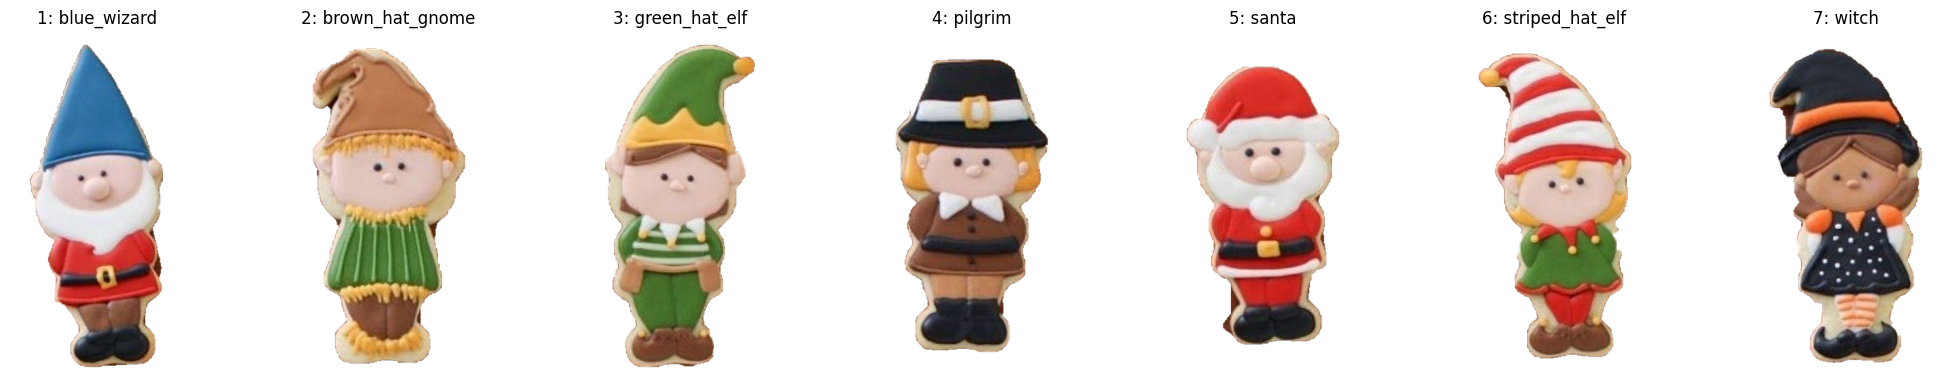

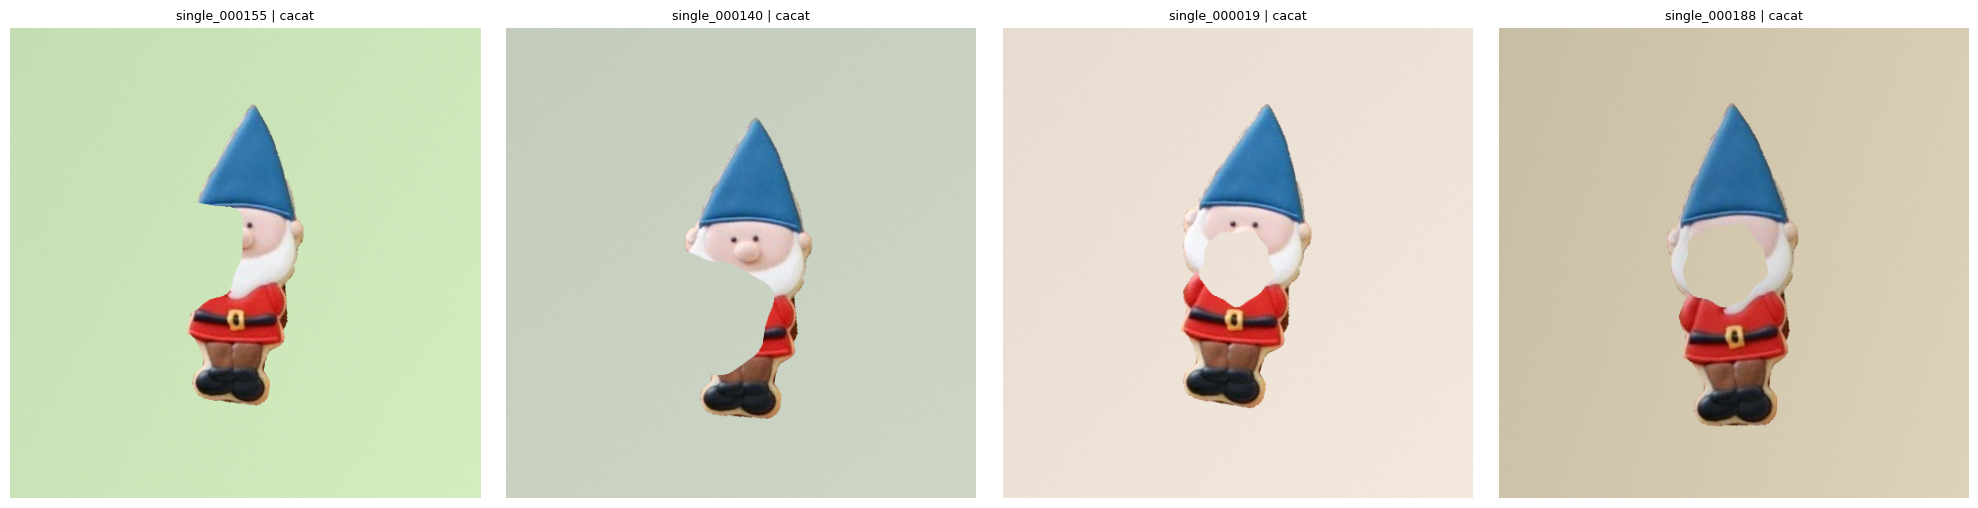

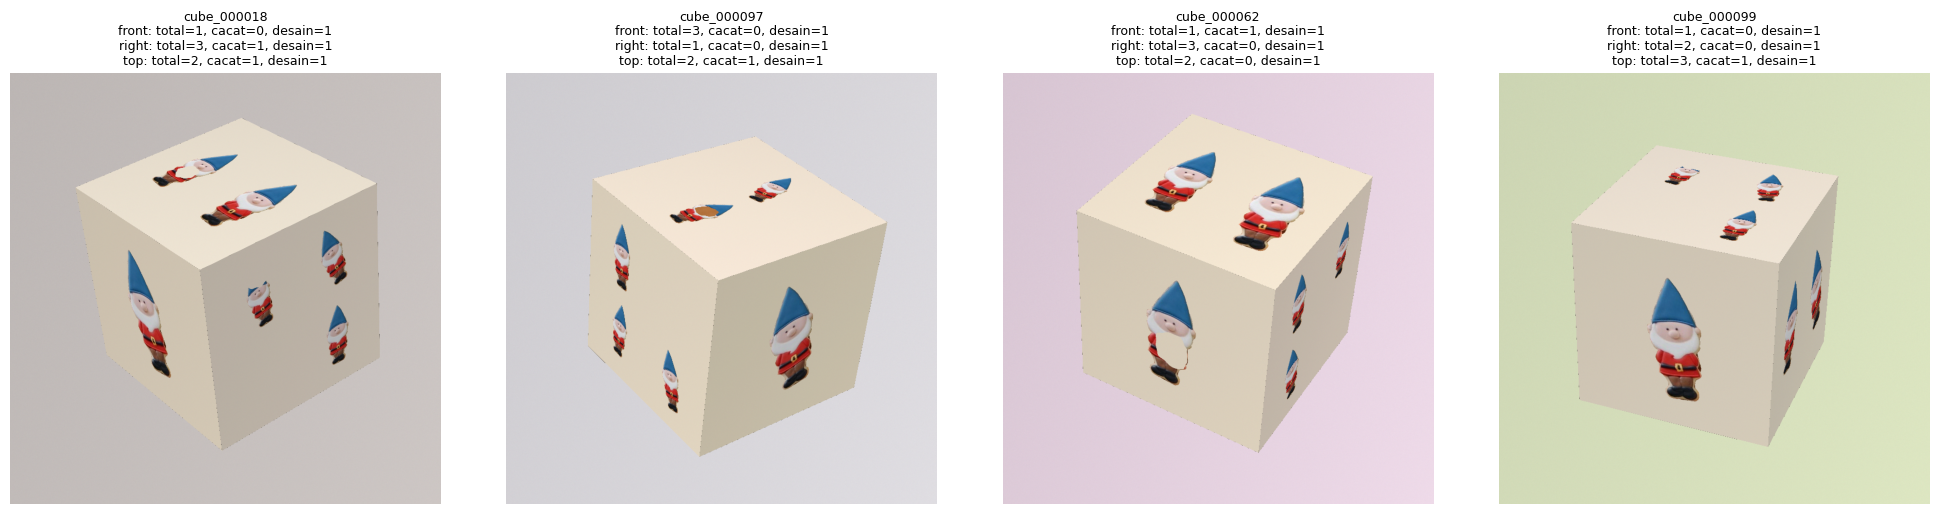

In [5]:
fig, axes = plt.subplots(1, len(references), figsize=(3*len(references),4), squeeze=False)
for ax, (design_id, ref) in zip(axes.ravel(), references.items()):
    ax.imshow(ref['rgba']); ax.set_title(f"{design_id}: {ref['name']}"); ax.axis('off')
plt.tight_layout(); plt.show()

def visualize_samples(index, labels=None, n=4, split='train'):
    subset = index[index['split'].eq(split)]
    if subset.empty:
        print(f'Tidak ada citra pada split {split}.'); return
    subset = subset.sample(min(n,len(subset)), random_state=SEED)
    fig, axes = plt.subplots(1,len(subset),figsize=(5*len(subset),5),squeeze=False)
    targets = {} if labels is None else labels.set_index('image_id').to_dict('index')
    for ax, row in zip(axes.ravel(), subset.itertuples()):
        ax.imshow(read_rgb(row.image_path)); ax.axis('off')
        title = row.image_id
        y = targets.get(row.image_id)
        if y is not None:
            if row.task == 'single':
                title += ' | cacat' if y['is_defective'] else ' | sempurna'
            else:
                title += '\n' + '\n'.join(f"{f}: total={y[f+'_total']}, cacat={y[f+'_defective']}, desain={y[f+'_design_count']}" for f in FACES)
        ax.set_title(title,fontsize=9)
    plt.tight_layout(); plt.show()

visualize_samples(single_index, single_labels)
visualize_samples(cube_index, cube_labels)

## 5. Data untuk pengembangan
Gunakan `train` untuk melatih metode dan `val` untuk memilih parameter/threshold. Gunakan `test` untuk evaluasi akhir. Jangan mengubah split berdasarkan hasil uji. Dataset satu desain belum cukup untuk menguji penghitungan desain unik.

Dataframe di bawah menyimpan path citra dan target. Muat citra sesuai kebutuhan agar penggunaan RAM terkontrol. Anotasi tambahan tersedia di folder `annotations` dan `masks`; tidak boleh digunakan sebagai masukan saat inferensi.

In [6]:
def labeled_split(index, labels, split):
    images = index[index['split'].eq(split)].copy()
    if labels is None:
        raise ValueError('Dataset ini tidak memiliki label.')
    out = images.merge(labels.drop(columns=['split','image'],errors='ignore'), on='image_id', how='left', validate='one_to_one', indicator=True)
    if not out['_merge'].eq('both').all():
        raise ValueError('Ada citra yang tidak memiliki label.')
    return out.drop(columns='_merge')

single_train = labeled_split(single_index, single_labels, 'train') if single_labels is not None else None
single_val = labeled_split(single_index, single_labels, 'val') if single_labels is not None else None
cube_train = labeled_split(cube_index, cube_labels, 'train') if cube_labels is not None else None
cube_val = labeled_split(cube_index, cube_labels, 'val') if cube_labels is not None else None

## 6. Implementasi

In [7]:
def predict_cube_dl(rgb, references):
    predictions, _ = dl.predict_cube(
        rgb,
        DL_FACE_MODEL,
        DL_FACE_SIZE,
        references,
        DL_REF_BANK,
        DL_EMBEDDER,
        DL_REF_EMB,
        DL_REF_IDS,
        DL_DEFECT_PAYLOAD,
        threshold_override=DL_DEFECT_THRESHOLD,
        max_defects_override=dl.MAX_DEFECTS_PER_CUBE,
    )
    return predictions


## 7. Validasi prediksi dan evaluasi

In [8]:
def validate_predictions(pred, expected_ids, task, leaderboard=False):
    cols = SINGLE_COLS if task == 'single' else cube_columns(leaderboard)
    if list(pred.columns) != cols:
        raise ValueError(f'Nama/urutan kolom wajib: {cols}')
    if pred.image_id.isna().any() or pred.image_id.duplicated().any():
        raise ValueError('ID kosong atau duplikat.')
    if set(pred.image_id) != set(expected_ids) or len(pred) != len(expected_ids):
        raise ValueError('ID hilang atau berlebih dibanding daftar citra.')
    values = pred[cols[1:]].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError('Prediksi memuat NaN/inf.')
    if task == 'single':
        if not pred.is_defective.isin([0,1]).all() or not pred.defect_score.between(0,1).all():
            raise ValueError('Label harus 0/1; defect_score harus 0–1.')
    else:
        if (values < 0).any() or not np.equal(values,np.floor(values)).all():
            raise ValueError('Hitungan wajib integer nonnegatif.')
        for f in FACES:
            if (pred[f+'_defective'] > pred[f+'_total']).any():
                raise ValueError('Jumlah cacat melebihi jumlah total.')
            if leaderboard:
                d,t = pred[f+'_design_count'],pred[f+'_total']
                if ((d>t)|(d>len(references))|((t>0)&(d==0))).any():
                    raise ValueError('Jumlah desain unik tidak konsisten.')
    return pred

def aligned_targets(pred, truth, cols):
    if truth is None:
        raise ValueError('Evaluasi tidak tersedia: hidden dataset tidak memiliki label.')
    if truth.image_id.duplicated().any():
        raise ValueError('ID ground truth duplikat.')
    indexed = truth.set_index('image_id')
    missing = set(pred.image_id)-set(indexed.index)
    if missing:
        raise ValueError(f'Ground truth tidak tersedia untuk {len(missing)} citra.')
    return indexed.loc[pred.image_id,cols].to_numpy(dtype=float)

def evaluate_single(pred, truth):
    y = aligned_targets(pred, truth, ['is_defective']).ravel().astype(int)
    p = pred.is_defective.to_numpy(dtype=int)
    return {'precision':precision_score(y,p,zero_division=0),
            'recall':recall_score(y,p,zero_division=0),
            'f1':f1_score(y,p,zero_division=0),
            'balanced_accuracy':balanced_accuracy_score(y,p) if len(np.unique(y))==2 else np.nan,
            'confusion_matrix_labels_0_1':confusion_matrix(y,p,labels=[0,1]).tolist()}

def evaluate_cube(pred, truth, leaderboard=False):
    fields = ['total','defective'] + (['design_count'] if leaderboard else [])
    cols = cube_columns(leaderboard)[1:]
    y = aligned_targets(pred,truth,cols)
    p = pred[cols].to_numpy(dtype=float)
    if len(p)==0:
        raise ValueError('Tidak ada prediksi untuk dievaluasi.')
    # Kolom diurutkan field dahulu, lalu face: N × K × 3.
    errors = np.abs(p-y).reshape(len(p),len(fields),3)
    result = {}
    for k, field in enumerate(fields):
        result['mae_'+field] = float(errors[:,k,:].mean())
        for j, face in enumerate(FACES):
            result[f'mae_{face}_{field}'] = float(errors[:,k,j].mean())
    result['exact_match_face_pct'] = float((errors==0).all(axis=1).mean()*100)
    result['exact_match_image_pct'] = float((errors==0).all(axis=(1,2)).mean()*100)
    bad_truth = y.reshape(len(p),len(fields),3)[:,1,:]
    positive = bad_truth > 0
    result['mae_defective_on_defective_faces'] = float(errors[:,1,:][positive].mean()) if positive.any() else None
    return result

## 8. Jalankan inferensi, evaluasi, dan simpan CSV

In [9]:
import json, pickle
from pathlib import Path
import numpy as np, cv2, torch, torch.nn.functional as F, pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier

def _face_probabilities(rgb, model, size):
    device = next(model.parameters()).device
    image = cv2.resize(rgb, (size, size), interpolation=cv2.INTER_LINEAR)
    image = (image.astype(np.float32) / 255.0 - dl.MEAN) / dl.STD
    tensor = torch.from_numpy(image.transpose(2, 0, 1))[None].to(device)
    with torch.inference_mode():
        return F.softmax(model(tensor), dim=1)[0].cpu().numpy()

def predict_face_map_tta(model, rgb, size=dl.FACE_INPUT):
    p = _face_probabilities(rgb, model, size)
    pf = _face_probabilities(rgb[:, ::-1].copy(), model, size)
    pf = pf[[0, 2, 1, 3]][:, :, ::-1]
    p = 0.5 * (p + pf)
    return cv2.resize(p.argmax(0).astype(np.uint8), (rgb.shape[1], rgb.shape[0]), interpolation=cv2.INTER_NEAREST)

def _reference_crop_and_mask(reference, size=224):
    if 'rgba' in reference:
        rgba = dl._ensure_uint8_rgba(reference['rgba']); rgb = rgba[:, :, :3]; mask = rgba[:, :, 3] > 0
    else:
        rgb = reference['rgb']; mask = reference['mask'].astype(bool)
    ys, xs = np.where(mask); x0, x1 = xs.min(), xs.max() + 1; y0, y1 = ys.min(), ys.max() + 1
    pad = int(dl.REFERENCE_PAD * max(x1 - x0, y1 - y0)); x0, y0 = max(0, x0 - pad), max(0, y0 - pad); x1, y1 = min(rgb.shape[1], x1 + pad), min(rgb.shape[0], y1 + pad)
    crop = rgb[y0:y1, x0:x1].copy(); cm = mask[y0:y1, x0:x1].copy(); side = max(crop.shape[:2])
    canvas = np.full((side, side, 3), 128, np.uint8); cmask = np.zeros((side, side), bool)
    oy, ox = (side - crop.shape[0]) // 2, (side - crop.shape[1]) // 2
    canvas[oy:oy+crop.shape[0], ox:ox+crop.shape[1]] = crop; cmask[oy:oy+crop.shape[0], ox:ox+crop.shape[1]] = cm
    return cv2.resize(canvas, (size, size)), cv2.resize(cmask.astype(np.uint8), (size, size), interpolation=cv2.INTER_NEAREST) > 0

def _synthetic_reference_variant(crop, mask, kind, rng):
    crop, mask = crop.copy(), mask.copy(); h, w = mask.shape[:2]
    if kind == 4:
        pass
    elif kind == 1:
        cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE); c = max(cnts, key=cv2.contourArea).reshape(-1, 2); point = c[rng.integers(0, len(c))]; r = int(rng.uniform(0.06, 0.16) * max(h, w)); cv2.circle(crop, tuple(point), r, (128,128,128), -1); cv2.circle(mask.view(np.uint8), tuple(point), r, 0, -1)
    elif kind == 2:
        r = int(rng.uniform(0.05, 0.13) * max(h, w)); k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*r+1,)*2); valid = cv2.erode(mask.astype(np.uint8), k) > 0
        if valid.any():
            vy, vx = np.where(valid); idx = rng.integers(0, len(vx)); center = (int(vx[idx]), int(vy[idx])); cv2.circle(crop, center, r, (128,128,128), -1); cv2.circle(mask.view(np.uint8), center, r, 0, -1)
    else:
        r = int(rng.uniform(0.07, 0.17) * max(h, w)); k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*r+1,)*2); valid = cv2.erode(mask.astype(np.uint8), k) > 0
        if valid.any():
            vy, vx = np.where(valid); idx = rng.integers(0, len(vx)); center = (int(vx[idx]), int(vy[idx])); pixels = crop[mask]; order = np.argsort(pixels.mean(1)); body = pixels[order[:max(10, len(order)//2)]]; color = np.median(body, axis=0).astype(np.uint8) if len(pixels) else np.array([180,120,80], np.uint8); cv2.circle(crop, center, r, tuple(int(v) for v in color), -1); crop = cv2.GaussianBlur(crop, (5,5), 0)
    ang, sc = rng.uniform(-20,20), rng.uniform(0.88,1.12); M = cv2.getRotationMatrix2D((w/2,h/2), ang, sc); M[0,2] += rng.uniform(-0.06,0.06)*w; M[1,2] += rng.uniform(-0.06,0.06)*h
    crop = cv2.warpAffine(crop, M, (w,h), flags=cv2.INTER_LINEAR, borderValue=(128,128,128)); mask = cv2.warpAffine(mask.astype(np.uint8), M, (w,h), flags=cv2.INTER_NEAREST, borderValue=0) > 0
    return crop, mask

def build_reference_embeddings_v2(embedder, references, variants_per_design=9):
    rng = np.random.default_rng(dl.SEED); crops, ids = [], []
    for did, ref in references.items():
        clean, cm = _reference_crop_and_mask(ref); crops.append(clean); ids.append((did, 0))
        for k in range(max(4, variants_per_design // 2)):
            v, vm = _synthetic_reference_variant(clean, cm, 4, rng)
            crops.append(v); ids.append((did, 4))
        for k in range(variants_per_design):
            kind = 1 + (k % 3); v, vm = _synthetic_reference_variant(clean, cm, kind, rng)
            if vm.sum() < 0.25 * cm.sum(): v, vm = clean, cm
            crops.append(v); ids.append((did, kind))
    return embedder.embed(crops), ids

_ROBUST_CACHE = {}
def _reference_descriptor(design_id, reference):
    if design_id in _ROBUST_CACHE: return _ROBUST_CACHE[design_id]
    crop, mask = _reference_crop_and_mask(reference); m8 = mask.astype(np.uint8)
    cnts, _ = cv2.findContours(m8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE); c = max(cnts, key=cv2.contourArea)
    hsv = cv2.cvtColor(crop, cv2.COLOR_RGB2HSV); hist = cv2.calcHist([hsv], [0,1], m8, [30,32], [0,180,0,256]); cv2.normalize(hist, hist, 0, 1, cv2.NORM_MINMAX)
    white = ((hsv[:,:,2] > 150) & (hsv[:,:,1] < 80) & mask).sum() / (mask.sum() + 1e-6)
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY); edge = ((cv2.Canny(gray, 30, 100) > 0) & mask).sum() / (mask.sum() + 1e-6)
    _ROBUST_CACHE[design_id] = {'contour': c, 'hist': hist, 'white': white, 'edge': edge}
    return _ROBUST_CACHE[design_id]

def _content_features(crop, mask, design_id, reference):
    rd = _reference_descriptor(design_id, reference); m8 = mask.astype(np.uint8)
    cnts, _ = cv2.findContours(m8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE); c = max(cnts, key=cv2.contourArea) if cnts else None
    hull = cv2.convexHull(c) if c is not None else None
    solidity = float(m8.sum() / (cv2.contourArea(hull) + 1e-6)) if hull is not None else 0.0
    shape = float(cv2.matchShapes(c, rd['contour'], cv2.CONTOURS_MATCH_I1, 0)) if c is not None else 10.0
    hsv = cv2.cvtColor(crop, cv2.COLOR_RGB2HSV); hist = cv2.calcHist([hsv], [0,1], m8, [30,32], [0,180,0,256]); cv2.normalize(hist, hist, 0, 1, cv2.NORM_MINMAX); histd = float(cv2.compareHist(hist, rd['hist'], cv2.HISTCMP_BHATTACHARYYA))
    white = ((hsv[:,:,2] > 150) & (hsv[:,:,1] < 80) & mask).sum() / (mask.sum() + 1e-6); wd = abs(white - rd['white'])
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY); edge = ((cv2.Canny(gray, 30, 100) > 0) & mask).sum() / (mask.sum() + 1e-6); ed = abs(edge - rd['edge'])
    return {'solidity': solidity, 'shape_dist': shape, 'hist_dist': histd, 'white_diff': wd, 'edge_diff': ed, 'content_score': -shape - 2.0*histd - wd}

def compute_object_features_v3(warped_rgb, lab, actual_foreground, component, embedding, ref_bank, reference_embeddings, reference_ids, sift, matcher):
    sims = reference_embeddings @ embedding; by_design = {}
    for i, rid in enumerate(reference_ids):
        did, kind = rid if isinstance(rid, tuple) else (int(rid), 0); by_design.setdefault(did, {})
        by_design[did][kind] = max(by_design[did].get(kind, -1.0), float(sims[i]))
    clean_scores = {did: max(vals.get(0, -1.0), vals.get(4, -1.0)) for did, vals in by_design.items()}
    top_designs = sorted(clean_scores, key=lambda d: clean_scores[d], reverse=True)[:3]
    best_sim = clean_scores[top_designs[0]]
    if best_sim < 0.22: return None
    x, y, bw, bh = component['bbox']; crop = warped_rgb[y:y+bh, x:x+bw]; cm = component['comp_mask'][y:y+bh, x:x+bw]

    refined = []
    for did in top_designs:
        if best_sim - clean_scores[did] > 0.16: continue
        cf = _content_features(crop, cm, did, ref_bank[did]); refined.append((did, clean_scores[did], cf))
    design_id, best_similarity, content = max(refined, key=lambda item: item[2]['content_score'])

    if content['shape_dist'] > 4.0 and content['hist_dist'] > 0.85:
        return None
    if content['hist_dist'] > 0.85 and best_similarity < 0.40:
        return None
    margin = best_similarity - (clean_scores[top_designs[1]] if len(top_designs) > 1 else 0.0)
    clean_similarity = max(by_design[design_id].get(0, -1.0), by_design[design_id].get(4, -1.0)); variant_similarity = max([by_design[design_id].get(k, -1.0) for k in (1,2,3)], default=-1.0); variant_gap = float(variant_similarity - clean_similarity)
    reference = ref_bank[design_id]; h, w = warped_rgb.shape[:2]; pad = 12; x1, y1 = max(0, x-pad), max(0, y-pad); x2, y2 = min(w, x+bw+pad), min(h, y+bh+pad)
    crop_gray = cv2.cvtColor(warped_rgb[y1:y2, x1:x2], cv2.COLOR_RGB2GRAY); kp, des = sift.detectAndCompute(crop_gray, None); matrix = None; inliers = 0
    if des is not None and len(kp) >= 3:
        pts = np.array([k.pt for k in kp], np.float32) + np.array([x1, y1], np.float32); matches = matcher.knnMatch(reference['des'], des, k=2); good = [m for m, n in matches if m.distance < 0.75*n.distance]
        if len(good) >= 3:
            src = np.float32([reference['kp'][m.queryIdx].pt for m in good]).reshape(-1,1,2); dst = np.float32([pts[m.trainIdx] for m in good]).reshape(-1,1,2); matrix, mask = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC, ransacReprojThreshold=4.0); inliers = 0 if mask is None else int(mask.sum())
    coverage = overlap_fraction = stain_ratio = mean_delta_e = np.nan
    if matrix is not None and inliers >= 4:
        wm = cv2.warpAffine(reference['mask'], matrix, (w,h)) > 128; ra = wm.sum(); ov = np.logical_and(actual_foreground, wm); coverage = float(ov.sum()/(ra+1e-6)); overlap_fraction = float(ov.sum()/(component['comp_mask'].sum()+1e-6))
        if ov.sum() > 50:
            wr = cv2.warpAffine(reference['rgb'], matrix, (w,h)); rl = cv2.cvtColor(wr, cv2.COLOR_RGB2LAB).astype(np.float32); ls = np.median(lab[ov,0])/(np.median(rl[ov,0])+1e-6); rl[:,:,0] = np.clip(rl[:,:,0]*ls,0,255); inter = cv2.erode(ov.astype(np.uint8), np.ones((5,5),np.uint8)) > 0; gx = cv2.Sobel(rl[:,:,0],cv2.CV_32F,1,0,ksize=3); gy = cv2.Sobel(rl[:,:,0],cv2.CV_32F,0,1,ksize=3); nonedge = np.hypot(gx,gy) < 35.; de = np.linalg.norm(lab-rl,axis=2); st = np.logical_and.reduce([inter,nonedge,de>28.,lab[:,:,0]<(rl[:,:,0]-16.),lab[:,:,1]>129.,lab[:,:,2]>133.]).astype(np.uint8); nn,_,ss,_ = cv2.connectedComponentsWithStats(st); mx = max([ss[i,cv2.CC_STAT_AREA] for i in range(1,nn)], default=0); stain_ratio = float(mx/(ra+1e-6)); mean_delta_e = float(de[ov].mean())
    if np.isnan(mean_delta_e): mean_delta_e = 0.0
    if np.isnan(stain_ratio): stain_ratio = 0.0
    if np.isnan(coverage): coverage = 0.0
    if np.isnan(overlap_fraction): overlap_fraction = 0.0
    features = {'sim': best_similarity, 'margin': float(margin), 'inliers': float(inliers), 'coverage': coverage, 'overlap_frac': overlap_fraction, 'stain': stain_ratio, 'meande': mean_delta_e, 'area': float(component['area']), 'aspect': float(bw)/max(1.0,float(bh)), 'cov_def': max(0.0,1.0-coverage), 'sim_low': max(0.0,0.75-best_similarity), 'clean_sim': float(clean_similarity), 'variant_sim': float(variant_similarity), 'variant_gap': variant_gap, 'alignment_valid': int(inliers >= 8), **content}
    return {'bbox': component['bbox'], 'design_id': design_id, 'design_name': reference['name'], 'features': features}

EXTENDED_FEATURES = [
    'sim', 'margin', 'inliers', 'coverage', 'overlap_frac', 'stain', 'meande',
    'area', 'aspect', 'cov_def', 'sim_low', 'clean_sim', 'variant_gap',
    'alignment_valid', 'solidity', 'shape_dist', 'hist_dist', 'white_diff',
    'edge_diff', 'content_score',
]
DEFECT_THRESHOLD_V8 = 0.74


def train_defect_classifier_v8(
    train_root, face_model, face_size, ref_bank, embedder,
    reference_embeddings, reference_ids, output_path,
    features_path=None,
):
    """Train a defect classifier with the extended, design-relative features."""
    train_root = Path(train_root)
    annotations = json.loads((train_root / 'cube_annotations.json').read_text())
    rows = []
    for index, annotation in enumerate(annotations):
        if annotation['split'] != 'train':
            continue
        rows.extend(
            dl._objects_from_annotation(
                annotation, train_root, face_model, face_size, ref_bank,
                embedder, reference_embeddings, reference_ids,
            )
        )
        if (index + 1) % 20 == 0:
            print(f'features: {index + 1}/{len(annotations)}', flush=True)

    frame = pd.DataFrame(rows)
    if features_path is not None:
        Path(features_path).parent.mkdir(parents=True, exist_ok=True)
        frame.to_csv(features_path, index=False)

    train_frame = frame[(frame['iou'] > 0.3) & frame['y'].notna()].copy()
    X = train_frame[EXTENDED_FEATURES].replace([np.inf, -np.inf], np.nan).fillna(-1)
    y = train_frame['y'].astype(int)
    model = HistGradientBoostingClassifier(
        max_depth=3,
        max_iter=400,
        learning_rate=0.04,
        class_weight='balanced',
        random_state=dl.SEED,
    )
    model.fit(X, y)
    payload = {
        'model': model,
        'features': EXTENDED_FEATURES,
        'threshold': DEFECT_THRESHOLD_V8,
        'max_defects': dl.MAX_DEFECTS_PER_CUBE,
    }
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with open(output_path, 'wb') as handle:
        pickle.dump(payload, handle)
    print(f'Defect classifier saved to {output_path} ({len(train_frame)} objects)')
    return payload


_ORIGINAL_PREDICT_CUBE = dl.predict_cube
def predict_cube_v2(rgb, face_model, face_size, references, ref_bank, embedder, reference_embeddings, reference_ids, defect_payload=None, threshold_override=None, max_defects_override=None):
    pred, debug = _ORIGINAL_PREDICT_CUBE(rgb, face_model, face_size, references, ref_bank, embedder, reference_embeddings, reference_ids, defect_payload, threshold_override, max_defects_override)
    objects = debug.get('objects', [])
    for obj in objects:
        f = obj['features']; p = float(obj.get('defect_probability', 0.0)); valid = f['inliers'] >= 8; vg = float(f.get('variant_gap', 0.0)); shape = float(f.get('shape_dist', 0.0)); hist = float(f.get('hist_dist', 0.0)); white = float(f.get('white_diff', 0.0)); area = f['area']; sim = f['sim']

        strong_variant = (
            vg >= 0.10 and sim >= 0.30 and area >= 1500
            and shape < 2.0 and hist < 0.65
            and (f['coverage'] > 0.05 or sim >= 0.45)
        )
        strong_shape = shape > 1.0 and sim >= 0.35 and area >= 1500
        strong_stain = valid and f['stain'] >= 0.05 and hist < 0.65
        strong_coverage = (
            valid and 0.10 < f['coverage'] < 0.80
            and vg >= 0.03 and shape < 2.0
        )
        strong = strong_variant or strong_shape or strong_stain or strong_coverage
        if strong:
            p = max(p, 0.85)
        if not valid and not strong:
            p = min(p, 0.35)
        if f['coverage'] <= 0.01 and not strong:
            p = min(p, 0.35)
        if valid and f['coverage'] >= 0.90 and f['stain'] < 0.02 and shape < 0.5 and hist < 0.35 and vg < 0.03 and not strong:
            p = min(p, 0.45)
        obj['defect_probability'] = float(p)
    if defect_payload is None:
        th = dl.DEFECT_THRESHOLD if threshold_override is None else threshold_override; mx = dl.MAX_DEFECTS_PER_CUBE if max_defects_override is None else max_defects_override
    else:
        th = float(defect_payload.get('threshold', dl.DEFECT_THRESHOLD)) if threshold_override is None else float(threshold_override); mx = int(defect_payload.get('max_defects', dl.MAX_DEFECTS_PER_CUBE)) if max_defects_override is None else int(max_defects_override)
    ranked = sorted(objects, key=lambda o: o['defect_probability'], reverse=True); selected = {id(o) for o in ranked[:mx] if o['defect_probability'] >= th}
    for o in objects: o['is_defective'] = id(o) in selected
    out = {}
    for face in dl.FACES:
        ff = [o for o in objects if o['face'] == face]; out[f'{face}_total'] = len(ff); out[f'{face}_defective'] = sum(int(o['is_defective']) for o in ff); out[f'{face}_design_count'] = len({o['design_id'] for o in ff})
    return out, debug


def _clean_face_mask(mask, k=15):
    m = (mask > 0).astype(np.uint8) * 255
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    eroded = cv2.erode(m, kernel)
    count, labels, stats, _ = cv2.connectedComponentsWithStats(eroded)
    if count <= 1:
        return m
    label_id = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    kept = (labels == label_id).astype(np.uint8) * 255
    kept = cv2.dilate(kept, kernel)
    if kept.sum() < 0.35 * max(1, m.sum()):
        return m
    return kept


def extract_faces_clean(rgb, face_map, out_size=512):
    dst = np.array(
        [[0, 0], [out_size - 1, 0], [out_size - 1, out_size - 1], [0, out_size - 1]],
        dtype=np.float32,
    )
    faces = {}
    for face in dl.FACES:
        mask = _clean_face_mask(face_map == dl.FACE_TO_ID[face], k=15)
        if (mask > 0).sum() < 500:
            faces[face] = None
            continue
        quad = dl.mask_to_quad(mask)
        if quad is None:
            faces[face] = None
            continue
        matrix = cv2.getPerspectiveTransform(quad, dst)
        warped = cv2.warpPerspective(rgb, matrix, (out_size, out_size))
        faces[face] = {"corners": quad, "warped": warped, "M": matrix}
    return faces

predict_face_map = predict_face_map_tta
build_reference_embeddings = build_reference_embeddings_v2
extract_faces = extract_faces_clean
compute_object_features = compute_object_features_v3
train_defect_classifier = train_defect_classifier_v8
if not hasattr(dl, '_ORIGINAL_PREDICT_CUBE_BASE'):
    dl._ORIGINAL_PREDICT_CUBE_BASE = dl.predict_cube
predict_cube = dl._ORIGINAL_PREDICT_CUBE_BASE
dl.predict_face_map = predict_face_map
dl.build_reference_embeddings = build_reference_embeddings
dl.extract_faces = extract_faces
dl.compute_object_features = compute_object_features
dl.train_defect_classifier = train_defect_classifier
dl.predict_cube = predict_cube
dl.DINO_MIN_SIM = 0.22
DINO_MIN_SIM = 0.22

In [10]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

FACE_CKPT = MODEL_DIR / 'task2_face_unet.pt'
DEFECT_CKPT = MODEL_DIR / 'task2_defect_rf_v8.pkl'
DL_DEFECT_THRESHOLD = 0.74

if DL_DEFECT_THRESHOLD <= 0 or DL_DEFECT_THRESHOLD > 1:
    raise ValueError('DL_DEFECT_THRESHOLD harus berada pada (0, 1].')

# 1) Segmentasi sisi kubus (U-Net).
if not FACE_CKPT.exists():
    dl.train_face_model(ROOT, FACE_CKPT)
DL_FACE_MODEL, DL_FACE_SIZE = dl.load_face_model(FACE_CKPT)

# 2) Embedder DINOv2 + bank referensi SIFT.
DL_EMBEDDER = dl.DinoEmbedder()
DL_REF_EMB, DL_REF_IDS = dl.build_reference_embeddings(DL_EMBEDDER, references)
DL_REF_BANK = dl.build_reference_bank(references)

# 3) Classifier cacat referensi-relatif.
if not DEFECT_CKPT.exists():
    dl.train_defect_classifier(
        ROOT,
        DL_FACE_MODEL,
        DL_FACE_SIZE,
        DL_REF_BANK,
        DL_EMBEDDER,
        DL_REF_EMB,
        DL_REF_IDS,
        DEFECT_CKPT,
        features_path=MODEL_DIR / 'task2_defect_features.csv',
    )
with open(DEFECT_CKPT, 'rb') as handle:
    DL_DEFECT_PAYLOAD = pickle.load(handle)

# 3b) Evaluasi opsional pada split test berlabel (desain training).
if cube_labels is not None and RUN_PREDICTIONS:
    eval_index = cube_index[cube_index['split'].eq(EVAL_SPLIT)]
    eval_rows = []
    for row in eval_index.itertuples():
        prediction = predict_cube_dl(read_rgb(row.image_path), references)
        for face in FACES:
            if prediction[f'{face}_total'] == 0:
                prediction[f'{face}_total'] = 1
                prediction[f'{face}_design_count'] = 1
        eval_rows.append({'image_id': row.image_id, **prediction})
    eval_pred = pd.DataFrame(eval_rows, columns=cube_columns(True))
    print(f'Metrik pada split {EVAL_SPLIT}:')
    print(pd.Series(evaluate_cube(eval_pred, cube_labels, leaderboard=True)).to_string())

# 4) Inferensi seluruh data submission.
if RUN_PREDICTIONS:
    hidden_submission = dl.run_prediction(
        repo_root=REPO_ROOT,
        hidden_root=HIDDEN_ROOT,
        reference_dir=REFERENCE_DIR,
        submission_dir=SUBMISSION_DIR,
        model_dir=MODEL_DIR,
        train_root=ROOT,
        defect_payload=DL_DEFECT_PAYLOAD,
        defect_threshold=DL_DEFECT_THRESHOLD,
        max_defects=dl.MAX_DEFECTS_PER_CUBE,
        save_debug=True,
    )
    print(hidden_submission.head().to_string())
    print('File submission:')
    print(' ', SUBMISSION_DIR / 'task2_dl_hidden_main.csv')
    print(' ', SUBMISSION_DIR / 'task2_dl_hidden_leaderboard.csv')
else:
    print('RUN_PREDICTIONS=False. Set True untuk membuat submission hidden.')

epoch 02/24 loss=0.2172 val_acc=0.8832 val_iou=[0.906, 0.561, 0.556, 0.755] (29.1s)


epoch 04/24 loss=0.0860 val_acc=0.9752 val_iou=[0.968, 0.951, 0.893, 0.896] (29.4s)


epoch 06/24 loss=0.0328 val_acc=0.9916 val_iou=[0.99, 0.978, 0.949, 0.973] (32.4s)


epoch 08/24 loss=0.0220 val_acc=0.9931 val_iou=[0.991, 0.977, 0.973, 0.98] (33.7s)


epoch 10/24 loss=0.0185 val_acc=0.9925 val_iou=[0.99, 0.985, 0.956, 0.976] (32.6s)


epoch 12/24 loss=0.0158 val_acc=0.9939 val_iou=[0.993, 0.985, 0.966, 0.978] (29.8s)


... (24 outputs left out)

predicted 160/200 (313.7s, 1.96s/image)


predicted 180/200 (349.2s, 1.94s/image)


predicted 200/200 (384.0s, 1.92s/image)


Saved debug object features: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\submissions\submission_tugas2_dl\task2_dl_hidden_objects.csv
Saved: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\submissions\submission_tugas2_dl\task2_dl_hidden_main.csv
Saved: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\submissions\submission_tugas2_dl\task2_dl_hidden_leaderboard.csv
Defects per image: {2: 90, 1: 68, 0: 42}
                image_id  front_total  right_total  top_total  front_defective  right_defective  top_defective  front_design_count  right_design_count  top_design_count
0  cube_043c007cea1e1da0            2            2          3                1                0              1                   2                   2                 2
1  cube_05d5a08c09734e6e            1            3          1                0                1              0                   1                   1 

## 9. Visualisasi prediksi DL untuk setiap citra hidden

Cell berikut menjalankan pipeline deep-learning pada **seluruh citra hidden** dan membuat gambar highlight untuk setiap citra:

- garis poligon tiga sisi kubus pada citra asli (`front`, `right`, `top`),
- hasil pelurusan setiap sisi,
- bounding box hijau untuk gingerbread yang diprediksi sempurna,
- bounding box merah untuk gingerbread yang diprediksi cacat,
- nama desain, skor cacat, kemiripan DINOv2, dan coverage SIFT/RANSAC.

Semua gambar disimpan ke `reports/task2_dl_visualizations/<image_id>.png`. Beberapa contoh pertama ditampilkan langsung di notebook; sisanya tetap tersimpan sebagai file.


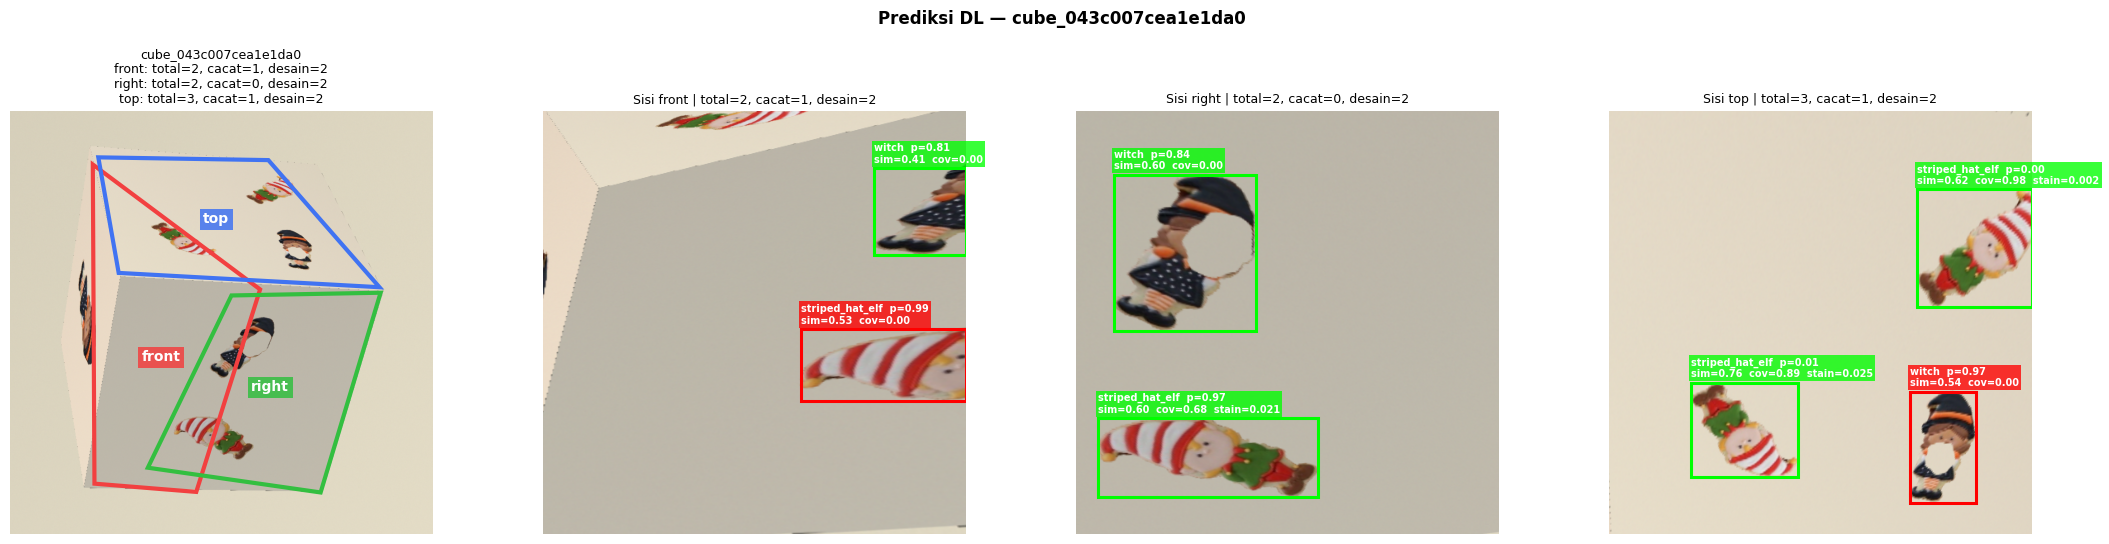

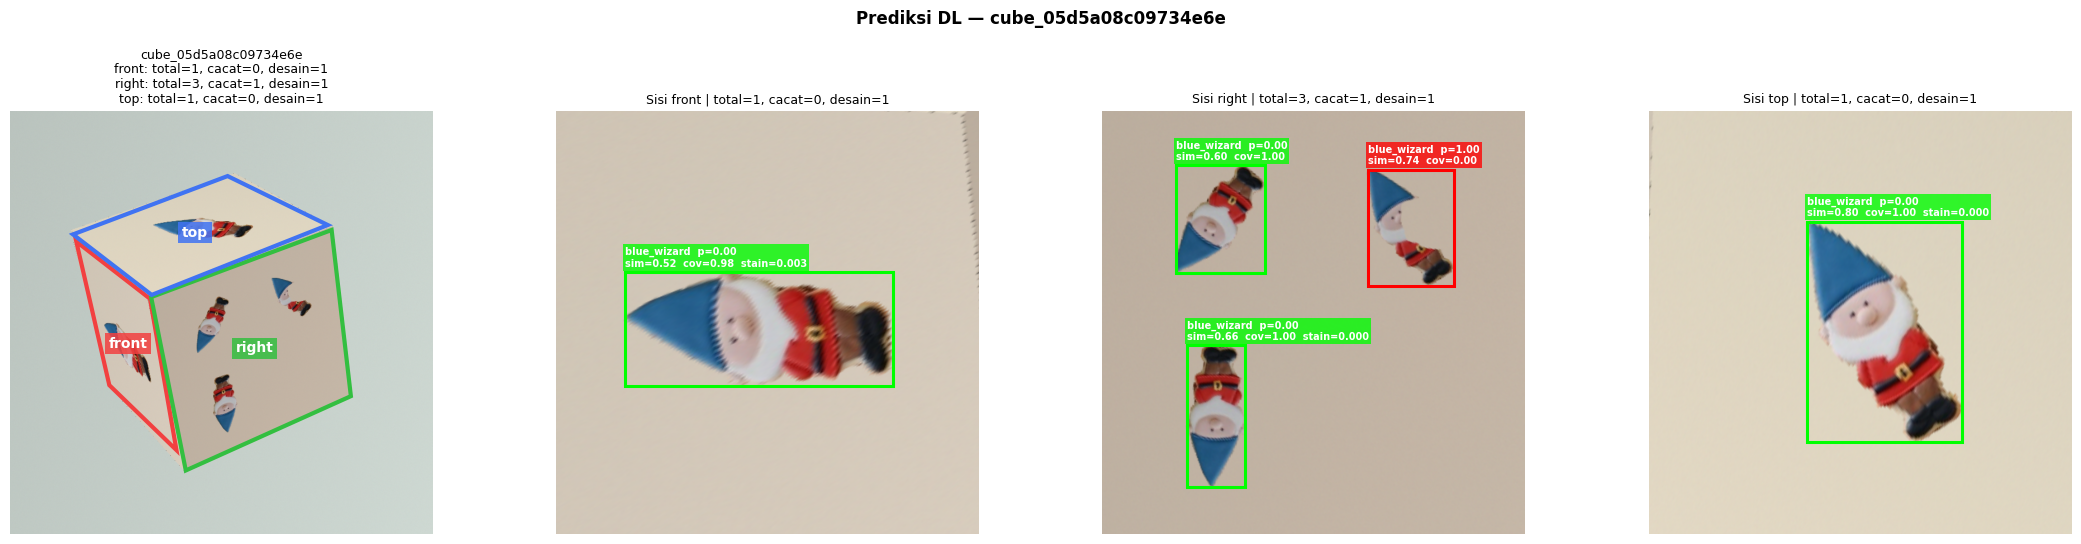

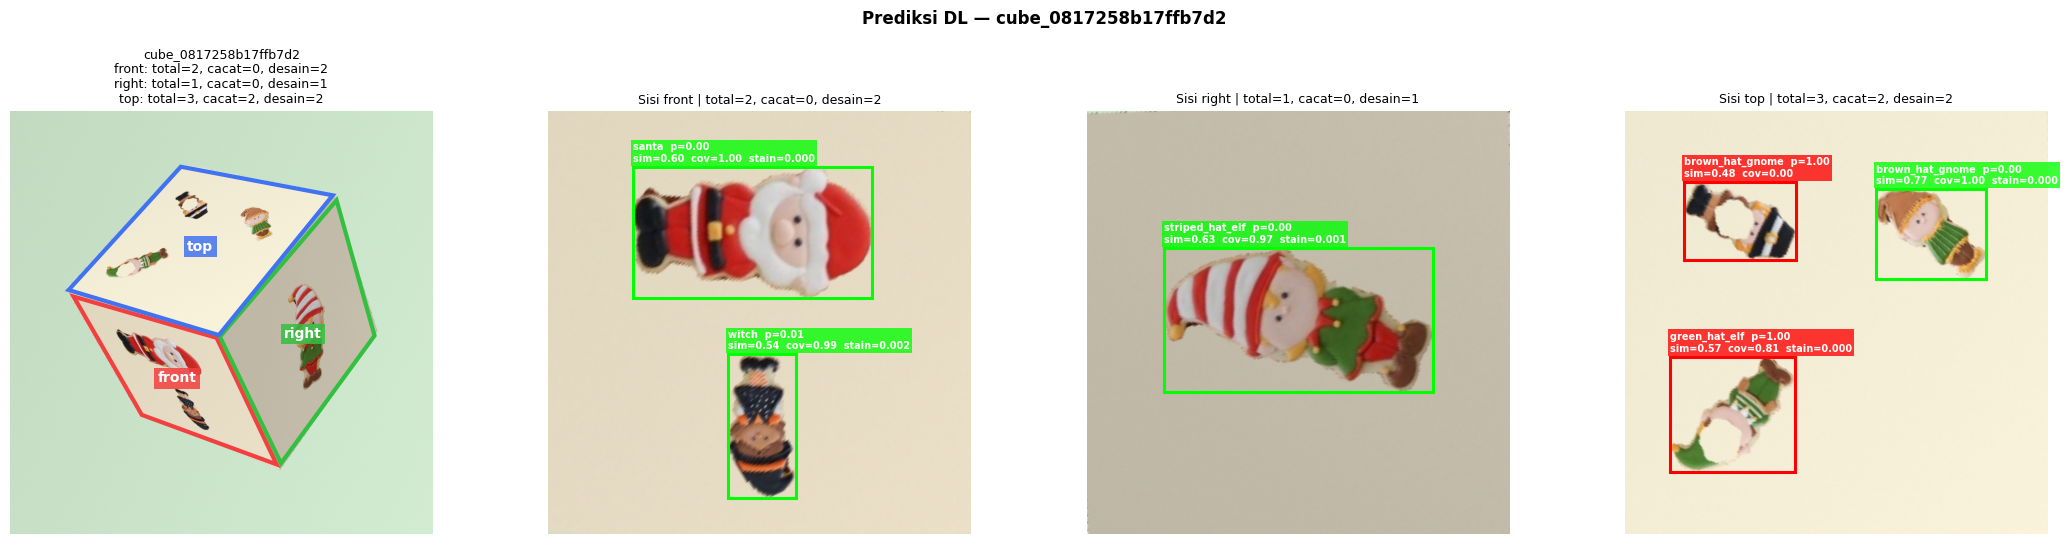

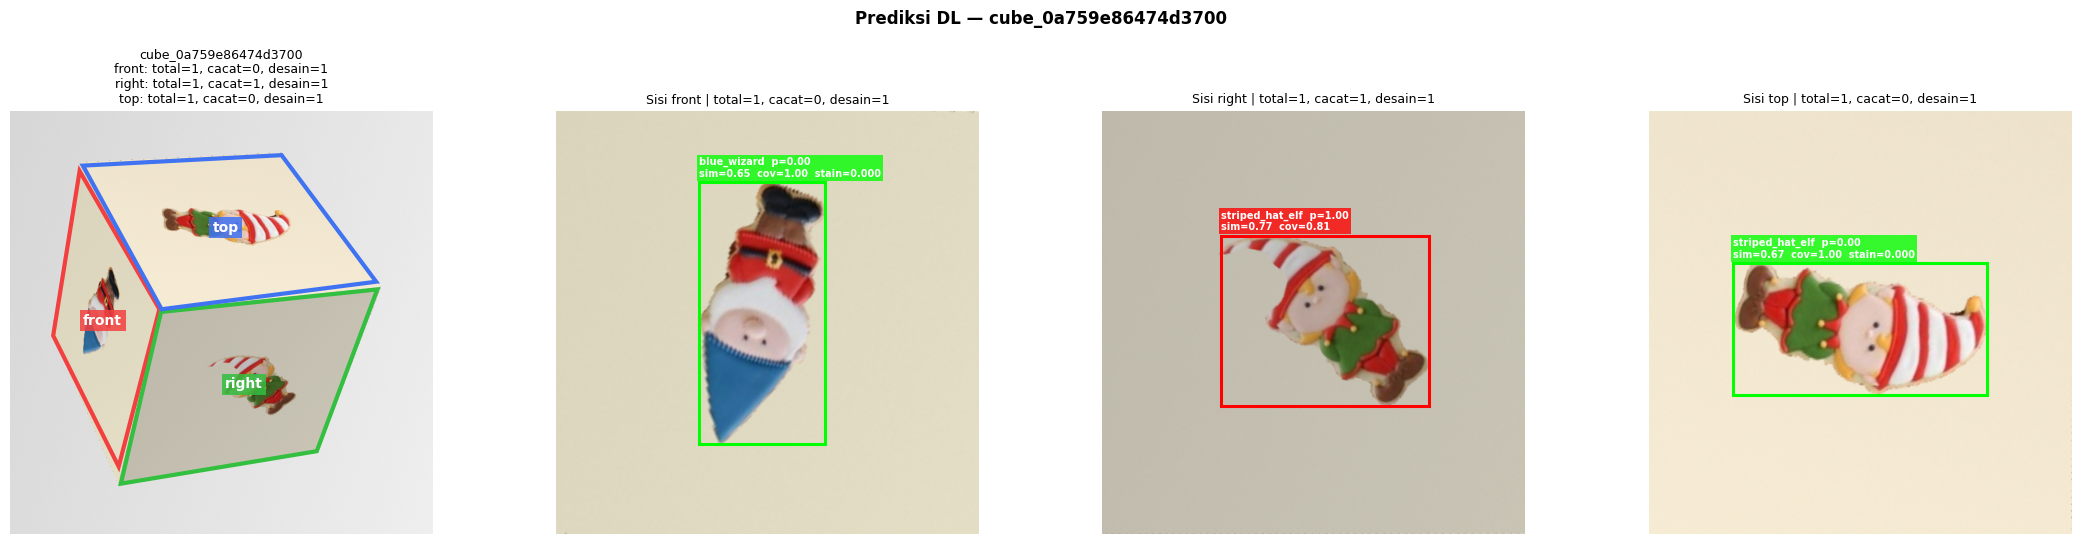

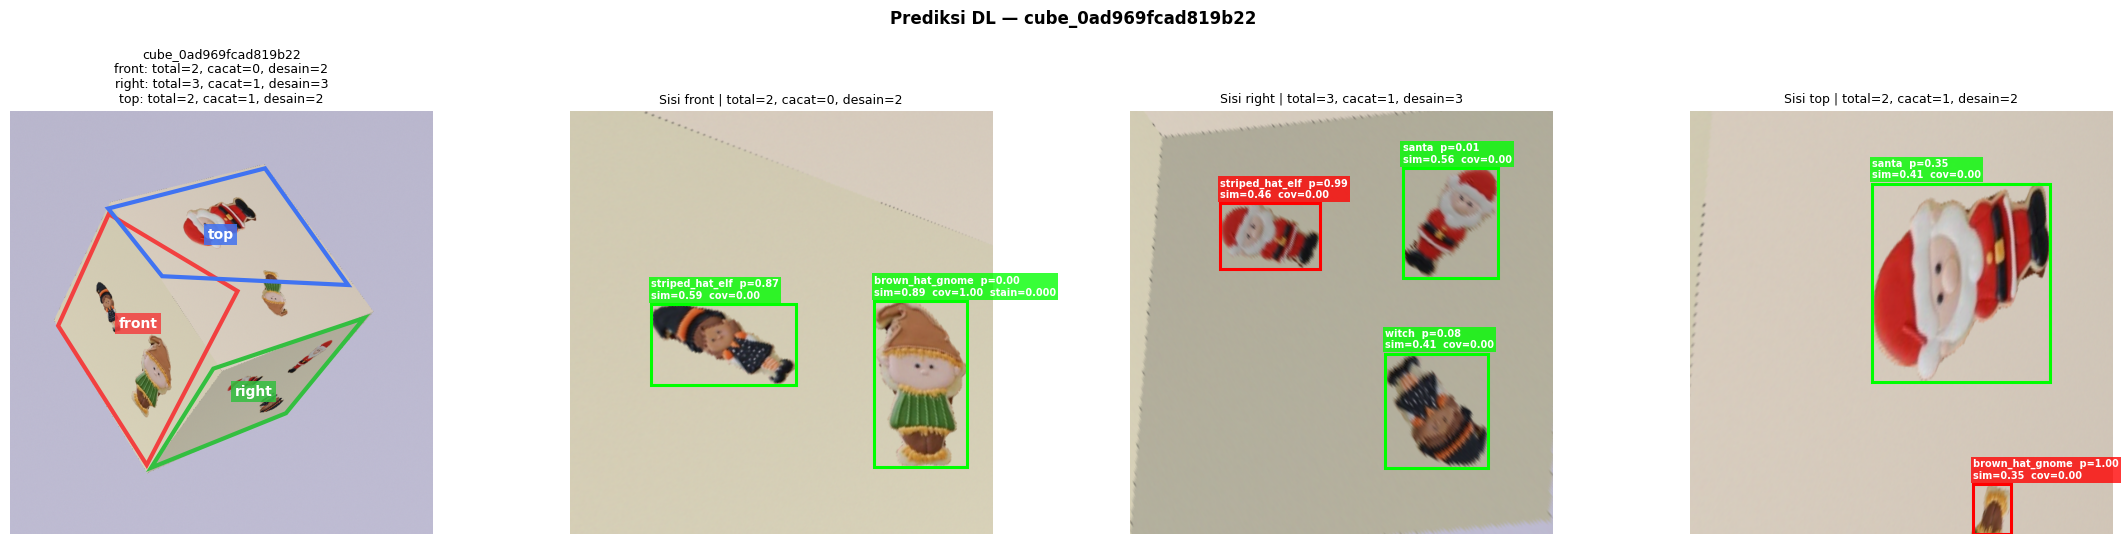

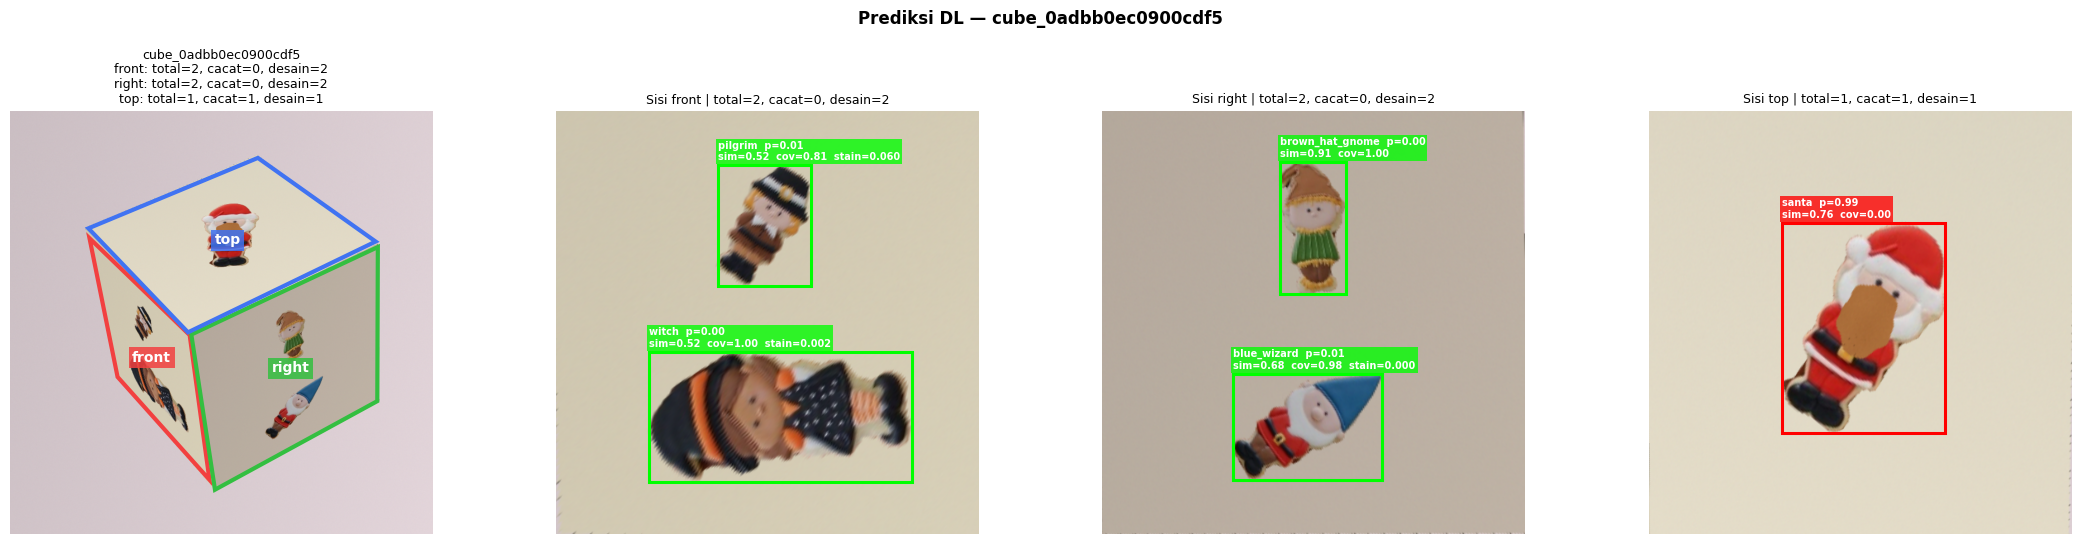

visualized 20/200 -> C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\reports\task2_dl_visualizations


visualized 40/200 -> C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\reports\task2_dl_visualizations


visualized 60/200 -> C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\reports\task2_dl_visualizations


visualized 80/200 -> C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\reports\task2_dl_visualizations


visualized 100/200 -> C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\reports\task2_dl_visualizations


visualized 120/200 -> C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\reports\task2_dl_visualizations


visualized 140/200 -> C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\reports\task2_dl_visualizations


visualized 160/200 -> C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\reports\task2_dl_visualizations


visualized 180/200 -> C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\reports\task2_dl_visualizations


visualized 200/200 -> C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\reports\task2_dl_visualizations
Semua visualisasi tersimpan di: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\reports\task2_dl_visualizations


In [11]:
VISUALIZATION_DIR = REPO_ROOT / 'reports' / 'task2_dl_visualizations'
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

VISUALIZE_ALL = True      # True: proses seluruh hidden_index
VISUALIZE_INLINE = 6      # jumlah contoh yang ditampilkan langsung di notebook
FACE_COLORS = {
    'front': (0.95, 0.25, 0.25),
    'right': (0.20, 0.75, 0.25),
    'top':   (0.25, 0.45, 0.95),
}


def _object_label(obj):
    features = obj['features']
    probability = obj.get('defect_probability', 0.0)
    first_line = f"{obj['design_name']}  p={probability:.2f}"
    second_line = (
        f"sim={features['sim']:.2f}  cov={features['coverage']:.2f}"
    )
    if features['stain'] > 0:
        second_line += f"  stain={features['stain']:.3f}"
    return first_line + "\n" + second_line


def visualize_cube_dl(image_id, image_path, show=False):
    """Buat satu gambar highlight: kubus asli + tiga sisi yang sudah diluruskan."""
    rgb = read_rgb(image_path)
    predictions, debug = dl.predict_cube(
        rgb,
        DL_FACE_MODEL,
        DL_FACE_SIZE,
        references,
        DL_REF_BANK,
        DL_EMBEDDER,
        DL_REF_EMB,
        DL_REF_IDS,
        DL_DEFECT_PAYLOAD,
        threshold_override=DL_DEFECT_THRESHOLD,
        max_defects_override=dl.MAX_DEFECTS_PER_CUBE,
    )

    fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))

    # Panel 0: citra kubus asli + poligon tiga sisi.
    ax = axes[0]
    ax.imshow(rgb)
    ax.axis('off')
    for face in FACES:
        face_debug = debug['faces'].get(face, {})
        corners = face_debug.get('corners')
        if corners is None:
            continue
        color = FACE_COLORS[face]
        polygon = patches.Polygon(
            corners, closed=True, fill=False, edgecolor=color, linewidth=3
        )
        ax.add_patch(polygon)
        cx, cy = np.mean(corners, axis=0)
        ax.text(
            cx, cy, face,
            color='white', fontsize=10, fontweight='bold',
            ha='center', va='center',
            bbox=dict(facecolor=color, alpha=0.85, pad=2.5, edgecolor='none'),
        )

    title_lines = [image_id]
    for face in FACES:
        title_lines.append(
            f"{face}: total={predictions[f'{face}_total']}, "
            f"cacat={predictions[f'{face}_defective']}, "
            f"desain={predictions[f'{face}_design_count']}"
        )
    ax.set_title("\n".join(title_lines), fontsize=9)

    # Panel 1..3: setiap sisi yang sudah diluruskan + highlight instance.
    for ax, face in zip(axes[1:], FACES):
        face_debug = debug['faces'].get(face, {})
        warped = face_debug.get('warped')
        if warped is None:
            ax.set_facecolor('#222222')
            ax.text(
                0.5, 0.5, f'Sisi {face} tidak terdeteksi',
                color='white', ha='center', va='center',
                transform=ax.transAxes, fontsize=10,
            )
            ax.axis('off')
            continue

        ax.imshow(warped)
        ax.axis('off')
        for obj in face_debug.get('objects', []):
            x, y, w, h = obj['bbox']
            color = 'red' if obj['is_defective'] else 'lime'
            ax.add_patch(
                patches.Rectangle(
                    (x, y), w, h, fill=False, edgecolor=color, linewidth=2.2
                )
            )
            ax.text(
                x, max(12, y - 4), _object_label(obj),
                color='white', fontsize=7, fontweight='bold', va='bottom',
                bbox=dict(facecolor=color, alpha=0.78, pad=1.5, edgecolor='none'),
            )

        ax.set_title(
            f"Sisi {face} | total={predictions[f'{face}_total']}, "
            f"cacat={predictions[f'{face}_defective']}, "
            f"desain={predictions[f'{face}_design_count']}",
            fontsize=9,
        )

    fig.suptitle(f"Prediksi DL — {image_id}", fontsize=12, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.95])

    output_path = VISUALIZATION_DIR / f"{image_id}.png"
    fig.savefig(output_path, dpi=110, bbox_inches='tight')
    if show:
        plt.show()
    plt.close(fig)
    return output_path


if RUN_PREDICTIONS:
    chosen = hidden_index if VISUALIZE_ALL else hidden_index.head(VISUALIZE_INLINE)
    for number, row in enumerate(chosen.itertuples(), start=1):
        output_path = visualize_cube_dl(
            row.image_id, row.image_path, show=(number <= VISUALIZE_INLINE)
        )
        if number % 20 == 0 or number == len(chosen):
            print(
                f"visualized {number}/{len(chosen)} "
                f"-> {output_path.parent}"
            )
    print('Semua visualisasi tersimpan di:', VISUALIZATION_DIR)
else:
    print('RUN_PREDICTIONS=False; visualisasi dilewati.')